# Sumativa 2: validación mediante simulación y remuestreo

**Asignatura:** Estadística Computacional  
**Integrantes:** Hernán Saavedra, Lenin Salas y Rodrigo Gómez  
**Dataset:** IBM HR Employee Attrition

## Objetivo

Evaluar la robustez de los resultados de la Sumativa 1 mediante bootstrap
no paramétrico, pruebas de permutación, simulación Monte Carlo y análisis
de sensibilidad.

El análisis utiliza el mismo conjunto sintético de 1.470 empleados y
35 variables, conservando las referencias numéricas de S1 para comparar
los resultados de ambas fases.

## Organización del análisis

1. Preparación de datos y referencias de la Sumativa 1.
2. Simulación Monte Carlo y evaluación de convergencia.
3. Validación de tres medias mediante intervalos bootstrap percentil y BCa.
4. Evaluación de estabilidad de cuatro correlaciones de Spearman.
5. Validación de la comparación de ingresos mediante permutación.
6. Análisis de influencia y sensibilidad a ingresos extremos.
7. Síntesis y exportación de resultados validados para la Sumativa 3.

## Alcance

Los métodos cuantifican incertidumbre bajo los supuestos de cada análisis.
El carácter sintético del dataset y la ausencia de un diseño de muestreo
real limitan la generalización de los resultados. Las asociaciones
observadas no permiten establecer relaciones causales.

## Aportes del equipo

- Hernán Saavedra: referencias de S1, simulación Monte Carlo e integración.
- Lenin Salas: bootstrap de medias y estabilidad de correlaciones.
- Rodrigo Gómez: prueba de permutación y análisis de robustez.

## Bloque A. Referencias de S1 y simulación Monte Carlo

In [2]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Buscar la raíz desde cualquier carpeta dentro del repositorio.
nombre_csv = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
carpeta_actual = Path.cwd().resolve()

raiz = next(
    (
        carpeta
        for carpeta in [carpeta_actual, *carpeta_actual.parents]
        if (carpeta / "datos" / nombre_csv).is_file()
    ),
    None
)

if raiz is None:
    raise FileNotFoundError(
        "No se encontró el dataset en la carpeta datos del repositorio."
    )

ruta_datos = raiz / "datos" / nombre_csv
ruta_notebook_s1 = raiz / "S1" / "Sumativa1_IBM_HR.ipynb"

if not ruta_notebook_s1.is_file():
    raise FileNotFoundError(
        f"No se encontró el notebook de referencia: {ruta_notebook_s1}"
    )

carpeta_figuras = raiz / "S2" / "figuras"
carpeta_resultados = raiz / "S2" / "resultados"

carpeta_figuras.mkdir(parents=True, exist_ok=True)
carpeta_resultados.mkdir(parents=True, exist_ok=True)

# Cargar el original y conservar una copia para el análisis.
original = pd.read_csv(ruta_datos)
df = original.copy(deep=True)

# Configuración de reproducibilidad.
SEMILLA = 42
N_ITERACIONES = 10_000

# Se crearán generadores independientes para cada procedimiento.
# Esto evita depender del orden de ejecución de otros bloques.
sns.set_theme(style="whitegrid")

huella_csv = hashlib.sha256(ruta_datos.read_bytes()).hexdigest()
# Normalizar los saltos de línea a LF para obtener una huella
# consistente entre Windows, Linux y macOS.
contenido_notebook_s1 = ruta_notebook_s1.read_bytes().replace(
    b"\r\n", b"\n"
).replace(b"\r", b"\n")

huella_notebook_s1 = hashlib.sha256(
    contenido_notebook_s1
).hexdigest()

versiones = {
    "Python": sys.version.split()[0],
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "SciPy": scipy.__version__,
    "Matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__
}

print("Raíz del repositorio:", raiz)
print(f"Dataset: {df.shape[0]} registros y {df.shape[1]} columnas")
print("Faltantes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("Semilla base:", SEMILLA)
print("Iteraciones previstas:", N_ITERACIONES)
print("SHA-256 del CSV:", huella_csv)

print("\nVersiones del entorno")
for biblioteca, version in versiones.items():
    print(f"{biblioteca}: {version}")

display(df.head())

Raíz del repositorio: C:\Users\hernan.saavedra\Documents\2026\Magister\Estadisticas\estadisticaComputacional
Dataset: 1470 registros y 35 columnas
Faltantes: 0
Filas duplicadas: 0
Semilla base: 42
Iteraciones previstas: 10000
SHA-256 del CSV: a5c31e38bd7fafc9bc333884eb181b06b41b8e5e488e8f7ccb27199fb3be7659

Versiones del entorno
Python: 3.11.9
pandas: 3.0.6
NumPy: 2.4.6
SciPy: 1.17.1
Matplotlib: 3.11.2
seaborn: 0.13.2


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


### A.1. Resultados de referencia de la Sumativa 1

Se reproducen las medias y los intervalos t del 95 % para ingreso mensual,
edad y antigüedad, utilizando el mismo dataset completo y procedimiento
de la Sumativa 1.

Los resultados se exportan sin redondear. El formato con coma decimal
se aplica únicamente a la presentación.

In [3]:
variables_medias = ["MonthlyIncome", "Age", "YearsAtCompany"]

referencias_medias = []

for variable in variables_medias:
    valores = df[variable].dropna()
    n = len(valores)
    media = valores.mean()
    desviacion = valores.std(ddof=1)
    error_estandar = stats.sem(valores)

    inferior, superior = stats.t.interval(
        confidence=0.95,
        df=n - 1,
        loc=media,
        scale=error_estandar
    )

    referencias_medias.append({
        "variable": variable,
        "n": n,
        "media": media,
        "desviacion_estandar": desviacion,
        "error_estandar": error_estandar,
        "ic95_inferior": inferior,
        "ic95_superior": superior,
        "metodo": "t de Student"
    })

referencias_medias = pd.DataFrame(referencias_medias)

# Mostrar una copia formateada.
presentacion = referencias_medias.copy()

columnas_decimales = [
    "media",
    "desviacion_estandar",
    "error_estandar",
    "ic95_inferior",
    "ic95_superior"
]

for columna in columnas_decimales:
    presentacion[columna] = presentacion[columna].map(
        lambda valor: f"{valor:.2f}".replace(".", ",")
    )

display(presentacion)

# Exportar valores numéricos con precisión suficiente para recuperarlos.
ruta_medias = carpeta_resultados / "S1_referencia_medias.csv"

referencias_medias.to_csv(
    ruta_medias,
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

print("Referencia guardada:", ruta_medias)

,variable,n,media,desviacion_estandar,error_estandar,ic95_inferior,ic95_superior,metodo
0,MonthlyIncome,1470,"6502,93","4707,96","122,79","6262,06","6743,80",t de Student
1,Age,1470,"36,92","9,14","0,24","36,46","37,39",t de Student
2,YearsAtCompany,1470,"7,01","6,13","0,16","6,69","7,32",t de Student


Referencia guardada: C:\Users\hernan.saavedra\Documents\2026\Magister\Estadisticas\estadisticaComputacional\S2\resultados\S1_referencia_medias.csv


### A.2. Correlaciones de referencia de la Sumativa 1

Se reproducen cuatro correlaciones de Spearman previamente examinadas:
ingreso con experiencia, edad con experiencia, antigüedad con experiencia
y distancia con ingreso.

La selección incluye asociaciones positivas y una cercana a cero.
Su estabilidad se evaluará posteriormente mediante remuestreo de filas
completas, conservando el emparejamiento de las variables.

In [4]:
pares_correlaciones = [
    ("MonthlyIncome", "TotalWorkingYears"),
    ("Age", "TotalWorkingYears"),
    ("YearsAtCompany", "TotalWorkingYears"),
    ("DistanceFromHome", "MonthlyIncome")
]

filas_correlaciones = []

for variable_x, variable_y in pares_correlaciones:
    pares_validos = df[[variable_x, variable_y]].dropna()

    rho = pares_validos[variable_x].corr(
        pares_validos[variable_y],
        method="spearman"
    )

    filas_correlaciones.append({
        "variable_x": variable_x,
        "variable_y": variable_y,
        "n": len(pares_validos),
        "rho_spearman": rho
    })

referencias_correlaciones = pd.DataFrame(filas_correlaciones)

# Formatear únicamente la presentación.
presentacion_correlaciones = referencias_correlaciones.copy()

presentacion_correlaciones["rho_spearman"] = (
    presentacion_correlaciones["rho_spearman"].map(
        lambda valor: f"{valor:.4f}".replace(".", ",")
    )
)

display(presentacion_correlaciones)

ruta_correlaciones = (
    carpeta_resultados / "S1_referencia_correlaciones.csv"
)

referencias_correlaciones.to_csv(
    ruta_correlaciones,
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

print("Referencia guardada:", ruta_correlaciones)

,variable_x,variable_y,n,rho_spearman
0,MonthlyIncome,TotalWorkingYears,1470,"0,7100"
1,Age,TotalWorkingYears,1470,"0,6569"
2,YearsAtCompany,TotalWorkingYears,1470,"0,5942"
3,DistanceFromHome,MonthlyIncome,1470,"0,0025"


Referencia guardada: C:\Users\hernan.saavedra\Documents\2026\Magister\Estadisticas\estadisticaComputacional\S2\resultados\S1_referencia_correlaciones.csv


### A.3. Pruebas y proporciones de referencia de la Sumativa 1

Se reproducen chi-cuadrado sin corrección de continuidad para horas extra
y salida, y t de Welch bilateral para ingreso mensual según salida.

La diferencia de ingresos se define como permanece menos sale.
También se conservan los tamaños y las proporciones de salida por horas
extra como entradas para la simulación Monte Carlo.

In [5]:
# Chi-cuadrado: horas extra y salida.
contingencia = pd.crosstab(
    df["OverTime"], df["Attrition"]
).reindex(index=["No", "Yes"], columns=["No", "Yes"])

chi2, p_chi2, gl_chi2, esperadas = stats.chi2_contingency(
    contingencia,
    correction=False
)

v_cramer = np.sqrt(chi2 / contingencia.to_numpy().sum())

# Welch: ingreso de quienes permanecen menos ingreso de quienes salen.
ingreso_no = df.loc[
    df["Attrition"].eq("No"), "MonthlyIncome"
].dropna()

ingreso_si = df.loc[
    df["Attrition"].eq("Yes"), "MonthlyIncome"
].dropna()

welch = stats.ttest_ind(
    ingreso_no,
    ingreso_si,
    equal_var=False,
    alternative="two-sided"
)

ic_diferencia = welch.confidence_interval(confidence_level=0.95)

referencias_pruebas = pd.DataFrame([
    {
        "prueba": "Chi-cuadrado sin correccion",
        "estadistico": chi2,
        "gl": gl_chi2,
        "valor_p": p_chi2,
        "v_cramer": v_cramer,
        "esperada_minima": esperadas.min(),
        "diferencia_medias": np.nan,
        "ic95_inferior": np.nan,
        "ic95_superior": np.nan
    },
    {
        "prueba": "Welch bilateral permanece menos sale",
        "estadistico": welch.statistic,
        "gl": welch.df,
        "valor_p": welch.pvalue,
        "v_cramer": np.nan,
        "esperada_minima": np.nan,
        "diferencia_medias": ingreso_no.mean() - ingreso_si.mean(),
        "ic95_inferior": ic_diferencia.low,
        "ic95_superior": ic_diferencia.high
    }
])

# Entradas de Monte Carlo: tamaños y proporciones observadas por grupo.
referencias_grupos = pd.DataFrame({
    "n": contingencia.sum(axis=1),
    "salidas": contingencia["Yes"]
})

referencias_grupos["proporcion_salida"] = (
    referencias_grupos["salidas"] / referencias_grupos["n"]
)

referencias_grupos.index.name = "OverTime"
referencias_grupos = referencias_grupos.reset_index()

# Exportar valores sin redondearlos.
referencias_pruebas.to_csv(
    carpeta_resultados / "S1_referencia_pruebas.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

referencias_grupos.to_csv(
    carpeta_resultados / "S1_referencia_grupos.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

print(f"Chi-cuadrado: {chi2:.4f}; p = {p_chi2:.6g}")
print(f"V de Cramér: {v_cramer:.4f}")
print(f"Welch: t = {welch.statistic:.4f}; p = {welch.pvalue:.6g}")
print(
    "Diferencia media:",
    f"{ingreso_no.mean() - ingreso_si.mean():.2f}"
)
print(
    "IC del 95 %:",
    f"[{ic_diferencia.low:.2f}; {ic_diferencia.high:.2f}]"
)

display(referencias_grupos)

Chi-cuadrado: 89.0439; p = 3.86152e-21
V de Cramér: 0.2461
Welch: t = 7.4826; p = 4.43359e-13
Diferencia media: 2045.65
IC del 95 %: [1508.24; 2583.05]


,OverTime,n,salidas,proporcion_salida
0,No,1054,110,0.104364
1,Yes,416,127,0.305288


### A.4. Registro de trazabilidad

Se registran las rutas, huellas SHA-256, versiones del entorno y archivos
de referencia. Las huellas permiten detectar cambios en el dataset
o en el notebook de S1.

Los cálculos anteriores reproducen los procedimientos de S1; su coincidencia
numérica es una comprobación de referencia, no una validación de robustez.
Esta última se realizará mediante bootstrap, permutación y sensibilidad.

In [6]:
archivos_referencia = [
    "S1_referencia_medias.csv",
    "S1_referencia_correlaciones.csv",
    "S1_referencia_pruebas.csv",
    "S1_referencia_grupos.csv"
]

registro = {
    "equipo": [
        "Hernán Saavedra",
        "Lenin Salas",
        "Rodrigo Gómez"
    ],
    "dataset": {
        "ruta": ruta_datos.relative_to(raiz).as_posix(),
        "sha256": huella_csv,
        "registros": len(df),
        "columnas": len(df.columns)
    },
    "notebook_s1": {
        "ruta": ruta_notebook_s1.relative_to(raiz).as_posix(),
        "sha256": huella_notebook_s1,
        "normalizacion": "Saltos de linea LF antes de calcular SHA-256"
    },
    "versiones": versiones,
    "semilla_base": SEMILLA,
    "iteraciones_previstas": N_ITERACIONES,
    "referencias": [
        {
            "ruta": (carpeta_resultados / nombre)
                .relative_to(raiz).as_posix(),
            "sha256": hashlib.sha256(
                (carpeta_resultados / nombre).read_bytes()
            ).hexdigest()
        }
        for nombre in archivos_referencia
    ]
}

ruta_registro = carpeta_resultados / "S1_trazabilidad.json"

ruta_registro.write_text(
    json.dumps(registro, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Registro creado:", ruta_registro)

for referencia in registro["referencias"]:
    print(referencia["ruta"])

Registro creado: C:\Users\hernan.saavedra\Documents\2026\Magister\Estadisticas\estadisticaComputacional\S2\resultados\S1_trazabilidad.json
S2/resultados/S1_referencia_medias.csv
S2/resultados/S1_referencia_correlaciones.csv
S2/resultados/S1_referencia_pruebas.csv
S2/resultados/S1_referencia_grupos.csv


### A.5. Diseño de la simulación Monte Carlo

Se simula el número de salidas en dos grupos hipotéticos con los mismos
tamaños y proporciones observadas en la Sumativa 1:

- Sin horas extra: 1.054 empleados y 110 salidas observadas.
- Con horas extra: 416 empleados y 127 salidas observadas.

En cada iteración se genera un conteo binomial por grupo. Se supone
que los empleados tienen una probabilidad de salida constante dentro
de cada grupo y que las salidas son independientes, también entre grupos.

Se mantienen fijos los parámetros estimados. La simulación representa
variabilidad del escenario condicionado a esos parámetros; no incorpora
todavía la incertidumbre de su estimación.

El escenario no tiene un horizonte temporal definido y no representa
una predicción para una empresa real. Tampoco estima el efecto causal
de modificar las horas extra.

In [7]:
# Leer las entradas exportadas desde nuestros resultados de S1.
entradas_mc = pd.read_csv(
    carpeta_resultados / "S1_referencia_grupos.csv",
    encoding="utf-8-sig",
    float_precision="round_trip"
).set_index("OverTime")

n_sin_extra = int(entradas_mc.loc["No", "n"])
n_con_extra = int(entradas_mc.loc["Yes", "n"])

p_sin_extra = float(entradas_mc.loc["No", "proporcion_salida"])
p_con_extra = float(entradas_mc.loc["Yes", "proporcion_salida"])

# Generador exclusivo para este procedimiento.
rng_mc = np.random.default_rng(
    np.random.SeedSequence([SEMILLA, 1])
)

salidas_sin_extra = rng_mc.binomial(
    n=n_sin_extra,
    p=p_sin_extra,
    size=N_ITERACIONES
)

salidas_con_extra = rng_mc.binomial(
    n=n_con_extra,
    p=p_con_extra,
    size=N_ITERACIONES
)

simulaciones_mc = pd.DataFrame({
    "iteracion": np.arange(1, N_ITERACIONES + 1),
    "salidas_sin_extra": salidas_sin_extra,
    "salidas_con_extra": salidas_con_extra
})

simulaciones_mc["salidas_totales"] = (
    simulaciones_mc["salidas_sin_extra"]
    + simulaciones_mc["salidas_con_extra"]
)

# Comparar porcentajes porque los grupos tienen tamaños diferentes.
simulaciones_mc["diferencia_pp"] = 100 * (
    simulaciones_mc["salidas_con_extra"] / n_con_extra
    - simulaciones_mc["salidas_sin_extra"] / n_sin_extra
)

esperanza_total = (
    n_sin_extra * p_sin_extra
    + n_con_extra * p_con_extra
)

diferencia_teorica_pp = 100 * (p_con_extra - p_sin_extra)

print("Iteraciones:", len(simulaciones_mc))
print(f"Salidas totales esperadas por el modelo: {esperanza_total:.2f}")
print(
    "Promedio de salidas totales simuladas:",
    f"{simulaciones_mc['salidas_totales'].mean():.2f}"
)
print(
    "Diferencia de proporciones usada como entrada:",
    f"{diferencia_teorica_pp:.2f} puntos porcentuales"
)
print(
    "Diferencia promedio simulada:",
    f"{simulaciones_mc['diferencia_pp'].mean():.2f} puntos porcentuales"
)

display(simulaciones_mc.head())

Iteraciones: 10000
Salidas totales esperadas por el modelo: 237.00
Promedio de salidas totales simuladas: 236.90
Diferencia de proporciones usada como entrada: 20.09 puntos porcentuales
Diferencia promedio simulada: 20.08 puntos porcentuales


,iteracion,salidas_sin_extra,salidas_con_extra,salidas_totales,diferencia_pp
0,1,117,105,222,14.139815
1,2,112,123,235,18.941122
2,3,110,135,245,22.015490
3,4,108,130,238,21.003321
4,5,120,130,250,19.864801


### A.6. Convergencia y error Monte Carlo

Se examina el promedio acumulado de salidas y su error estándar
Monte Carlo al aumentar el número de iteraciones.

El error Monte Carlo mide la precisión del promedio simulado condicionado
al modelo. No representa la incertidumbre de los parámetros estimados
en S1 ni la dispersión de los escenarios individuales.

Como comprobación, se compara el promedio simulado con la esperanza
analítica de 237 salidas.

,iteraciones,promedio_salidas,desviacion_escenarios,error_estandar_mc,margen_mc_95,diferencia_con_esperanza
0,100,"236,0700","15,3342","1,5334","3,0055","-0,9300"
1,500,"236,2120","14,1961","0,6349","1,2443","-0,7880"
2,1000,"236,7690","14,0388","0,4439","0,8701","-0,2310"
3,2000,"236,7535","13,9104","0,3110","0,6097","-0,2465"
4,5000,"236,8092","13,6215","0,1926","0,3776","-0,1908"
5,10000,"236,9038","13,7430","0,1374","0,2694","-0,0962"


Margen Monte Carlo final del 95 %: ±0.2694 salidas
Cumple la precisión objetivo de ±0,5 salidas: True


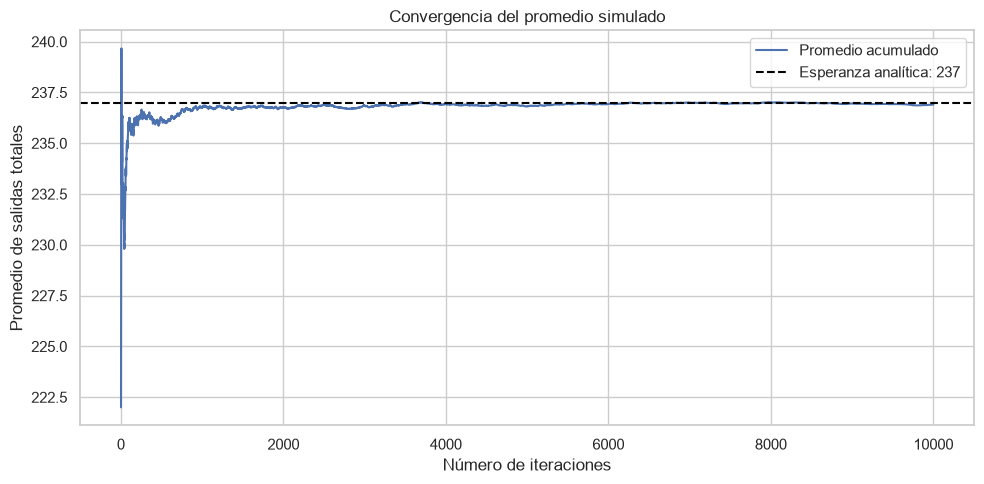

In [8]:
totales = simulaciones_mc["salidas_totales"].to_numpy()

puntos_revision = [100, 500, 1_000, 2_000, 5_000, 10_000]
filas_convergencia = []

for cantidad in puntos_revision:
    muestra = totales[:cantidad]

    promedio = muestra.mean()
    desviacion = muestra.std(ddof=1)
    error_mc = desviacion / np.sqrt(cantidad)

    filas_convergencia.append({
        "iteraciones": cantidad,
        "promedio_salidas": promedio,
        "desviacion_escenarios": desviacion,
        "error_estandar_mc": error_mc,
        "margen_mc_95": 1.96 * error_mc,
        "diferencia_con_esperanza": promedio - esperanza_total
    })

convergencia_mc = pd.DataFrame(filas_convergencia)

presentacion = convergencia_mc.copy()

for columna in presentacion.columns:
    if columna != "iteraciones":
        presentacion[columna] = presentacion[columna].map(
            lambda valor: f"{valor:.4f}".replace(".", ",")
        )

display(presentacion)

# Precisión objetivo para el promedio: margen MC de ±0,5 salidas.
tolerancia_mc = 0.5
margen_final = convergencia_mc.iloc[-1]["margen_mc_95"]

print(
    "Margen Monte Carlo final del 95 %:",
    f"±{margen_final:.4f} salidas"
)
print(
    "Cumple la precisión objetivo de ±0,5 salidas:",
    bool(margen_final <= tolerancia_mc)
)

# Promedio acumulado.
iteraciones = np.arange(1, len(totales) + 1)
promedio_acumulado = np.cumsum(totales) / iteraciones

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    iteraciones,
    promedio_acumulado,
    label="Promedio acumulado"
)

ax.axhline(
    esperanza_total,
    color="black",
    linestyle="--",
    label=f"Esperanza analítica: {esperanza_total:.0f}"
)

ax.set_xlabel("Número de iteraciones")
ax.set_ylabel("Promedio de salidas totales")
ax.set_title("Convergencia del promedio simulado")
ax.legend()

fig.tight_layout()
fig.savefig(
    carpeta_figuras / "hernan_mc_convergencia.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

convergencia_mc.to_csv(
    carpeta_resultados / "hernan_mc_convergencia.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

#### Interpretación de la convergencia

Con 10.000 iteraciones, el promedio simulado es de 236,9038 salidas,
frente a una esperanza analítica de 237. La diferencia es de −0,0962
salidas y la curva del promedio acumulado muestra estabilización.

El error estándar Monte Carlo es 0,1374 y el margen aproximado del
95 % es ±0,2694 salidas, inferior a la tolerancia definida de ±0,5.
Por tanto, la simulación alcanza la precisión computacional buscada
para estimar el promedio bajo este modelo.

La desviación estándar de los escenarios es 13,7430 salidas:
describe la variabilidad entre escenarios individuales y no debe
confundirse con el error estándar del promedio simulado.

Esta comprobación respalda la precisión numérica de la simulación,
pero no valida los supuestos del modelo ni incorpora la incertidumbre
de las proporciones estimadas en S1.

### A.7. Distribución de los escenarios simulados

Se calculan los percentiles 2,5 y 97,5 del número total de salidas
y de la diferencia de porcentajes entre grupos.

Estos límites describen el rango central aproximado del 95 % de los
escenarios bajo el modelo con parámetros fijos. No son intervalos
de confianza para los parámetros ni intervalos bootstrap.

La distribución simulada de la diferencia tampoco es un test de
permutación: se genera usando las proporciones observadas,
sin imponer una hipótesis nula de igualdad.

,variable,media,desviacion_estandar,percentil_2_5,mediana,percentil_97_5
0,salidas_totales,"236,90","13,74","210,00","237,00","264,00"
1,diferencia_pp,"20,08","2,44","15,28","20,09","24,84"


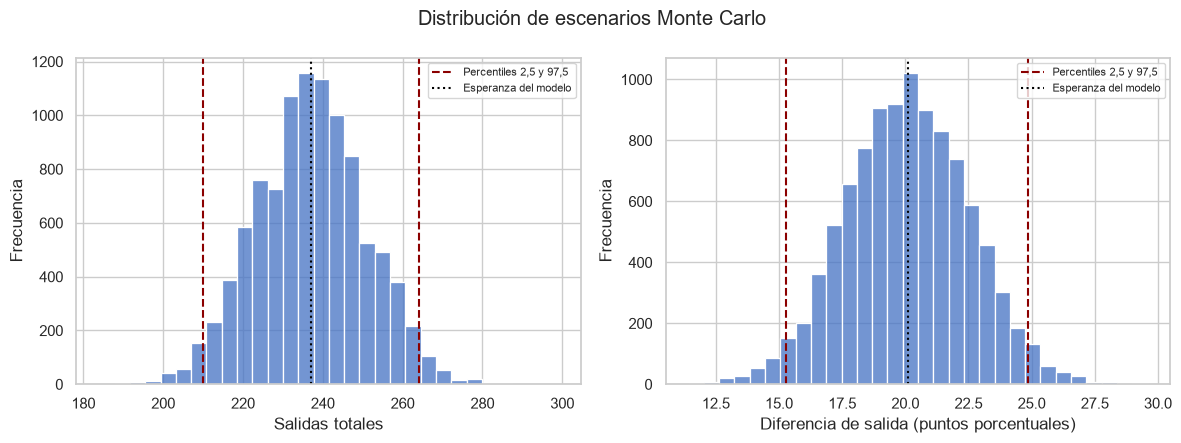

In [9]:
variables_escenarios = {
    "salidas_totales": "Salidas totales",
    "diferencia_pp": "Diferencia de salida (puntos porcentuales)"
}

filas_resumen = []

for variable, etiqueta in variables_escenarios.items():
    valores = simulaciones_mc[variable]

    filas_resumen.append({
        "variable": variable,
        "media": valores.mean(),
        "desviacion_estandar": valores.std(ddof=1),
        "percentil_2_5": valores.quantile(0.025),
        "mediana": valores.median(),
        "percentil_97_5": valores.quantile(0.975)
    })

resumen_mc = pd.DataFrame(filas_resumen)

presentacion = resumen_mc.copy()

for columna in presentacion.columns:
    if columna != "variable":
        presentacion[columna] = presentacion[columna].map(
            lambda valor: f"{valor:.2f}".replace(".", ",")
        )

display(presentacion)

# Visualizar ambas distribuciones.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (variable, etiqueta) in zip(
    axes, variables_escenarios.items()
):
    valores = simulaciones_mc[variable]
    inferior, superior = valores.quantile([0.025, 0.975])

    sns.histplot(
        valores,
        bins=30,
        color="#4472C4",
        ax=ax
    )

    ax.axvline(
        inferior,
        color="darkred",
        linestyle="--",
        label="Percentiles 2,5 y 97,5"
    )
    ax.axvline(
        superior,
        color="darkred",
        linestyle="--"
    )

    referencia = (
        esperanza_total
        if variable == "salidas_totales"
        else diferencia_teorica_pp
    )

    ax.axvline(
        referencia,
        color="black",
        linestyle=":",
        label="Esperanza del modelo"
    )

    ax.set_xlabel(etiqueta)
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=8)

fig.suptitle("Distribución de escenarios Monte Carlo")
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "hernan_mc_distribuciones.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Guardar simulaciones completas y resumen.
simulaciones_mc.to_csv(
    carpeta_resultados / "hernan_mc_simulaciones.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

resumen_mc.to_csv(
    carpeta_resultados / "hernan_mc_resumen.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

#### Interpretación de los escenarios

En las 10.000 simulaciones, el promedio de salidas totales fue 236,90
y la mediana 237. Los percentiles 2,5 y 97,5 fueron 210 y 264:
estos límites describen el rango central aproximado del 95 % de
los escenarios generados bajo el modelo.

La diferencia de porcentajes de salida entre quienes realizan horas
extra y quienes no las realizan tuvo una media simulada de 20,08
puntos porcentuales. Su rango central aproximado del 95 % se situó
entre 15,28 y 24,84 puntos porcentuales.

Estos resultados describen la variabilidad de escenarios hipotéticos
con tamaños y probabilidades fijos, tomados de S1. No constituyen
intervalos de confianza de los parámetros, una nueva prueba de
hipótesis ni una predicción anual.

La diferencia positiva refleja las probabilidades distintas utilizadas
como entradas. No demuestra un efecto causal de las horas extra.
La incertidumbre de esas probabilidades y posibles dependencias
entre empleados no están incorporadas en este modelo.

In [10]:
# Repetir la simulación con la misma semilla y el mismo orden.
rng_verificacion = np.random.default_rng(
    np.random.SeedSequence([SEMILLA, 1])
)

verificacion_sin_extra = rng_verificacion.binomial(
    n_sin_extra, p_sin_extra, size=N_ITERACIONES
)
verificacion_con_extra = rng_verificacion.binomial(
    n_con_extra, p_con_extra, size=N_ITERACIONES
)

assert np.array_equal(salidas_sin_extra, verificacion_sin_extra)
assert np.array_equal(salidas_con_extra, verificacion_con_extra)

# Comprobar que el archivo original de datos no fue modificado.
assert hashlib.sha256(ruta_datos.read_bytes()).hexdigest() == huella_csv

print("Reproducibilidad: correcta.")
print("Archivo original de datos: sin modificaciones.")
print(f"Iteraciones realizadas: {N_ITERACIONES:,}")

Reproducibilidad: correcta.
Archivo original de datos: sin modificaciones.
Iteraciones realizadas: 10,000


## Bloque B. Bootstrap de medias y correlaciones

In [11]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Buscar la raíz desde cualquier carpeta dentro del repositorio.
nombre_csv = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
carpeta_actual = Path.cwd().resolve()

raiz = next(
    (
        carpeta
        for carpeta in [carpeta_actual, *carpeta_actual.parents]
        if (carpeta / "datos" / nombre_csv).is_file()
    ),
    None
)

if raiz is None:
    raise FileNotFoundError(
        "No se encontró el dataset en la carpeta datos del repositorio."
    )

ruta_datos = raiz / "datos" / nombre_csv
carpeta_figuras = raiz / "S2" / "figuras"
carpeta_resultados = raiz / "S2" / "resultados"

carpeta_figuras.mkdir(parents=True, exist_ok=True)
carpeta_resultados.mkdir(parents=True, exist_ok=True)

# Cargar el original y trabajar sobre una copia.
original = pd.read_csv(ruta_datos)
df = original.copy(deep=True)

# Configuración de reproducibilidad.
SEMILLA = 42
B = 10_000          # remuestras bootstrap por variable y por par
ALFA = 0.05         # intervalos del 95 %
N = len(df)

sns.set_theme(style="whitegrid")

huella_csv = hashlib.sha256(ruta_datos.read_bytes()).hexdigest()

print("Raíz del repositorio:", raiz)
print("Registros:", N, "| Columnas:", df.shape[1])
print("Remuestras por estadístico:", f"{B:,}".replace(",", "."))
print("Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| NumPy", np.__version__, "| SciPy", scipy.__version__,
      "| Matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

Raíz del repositorio: C:\Users\hernan.saavedra\Documents\2026\Magister\Estadisticas\estadisticaComputacional
Registros: 1470 | Columnas: 35
Remuestras por estadístico: 10.000
Python 3.11.9 | pandas 3.0.6 | NumPy 2.4.6 | SciPy 1.17.1 | Matplotlib 3.11.2 | seaborn 0.13.2


### B.1. Lectura y verificación de las referencias S1

Se leen las referencias exportadas en el bloque de Hernán y se verifica,
con las huellas SHA-256 de `S1_trazabilidad.json`, que el dataset y las
referencias no cambiaron. Si alguna huella no coincide, el notebook se detiene. La comparación
normaliza los saltos de línea, porque Git puede convertirlos según el sistema
operativo de quien clona el repositorio.

In [30]:
def leer_csv(ruta):
    """Lee un CSV de referencia conservando todos los decimales."""
    return pd.read_csv(
        ruta, encoding="utf-8-sig", float_precision="round_trip"
    )

def sha256(ruta):
    return hashlib.sha256(ruta.read_bytes()).hexdigest()


def sha256_crlf(ruta):
    """Huella con saltos de línea CRLF, como en S1_trazabilidad.json.

    Git puede guardar los CSV con LF (Linux/macOS) o CRLF (Windows) según la
    configuración de cada integrante; el contenido es el mismo. Se normaliza
    a CRLF para comparar con las huellas registradas en Windows.
    """
    contenido = ruta.read_bytes().replace(b"\r\n", b"\n")
    return hashlib.sha256(contenido.replace(b"\n", b"\r\n")).hexdigest()

trazabilidad = json.loads(
    (carpeta_resultados / "S1_trazabilidad.json").read_text(encoding="utf-8")
)

assert trazabilidad["dataset"]["sha256"] in (
    sha256(ruta_datos), sha256_crlf(ruta_datos)
), (
    "El dataset no coincide con el usado en S1."
)

for referencia in trazabilidad["referencias"]:
    ruta = raiz / referencia["ruta"]
    assert referencia["sha256"] in (
    sha256(ruta), sha256_crlf(ruta)
), (
        f"La referencia cambió: {ruta.name}"
    )

# Huellas al inicio, para comprobar al final que no se modificaron.
huellas_referencias = {
    ruta.name: sha256(ruta)
    for ruta in sorted(carpeta_resultados.glob("S1_referencia_*.csv"))
}

ref_medias = leer_csv(carpeta_resultados / "S1_referencia_medias.csv")
ref_correlaciones = leer_csv(
    carpeta_resultados / "S1_referencia_correlaciones.csv"
)

print("Dataset y referencias verificados contra S1_trazabilidad.json.")
display(ref_medias)
display(ref_correlaciones)

Dataset y referencias verificados contra S1_trazabilidad.json.


,variable,n,media,desviacion_estandar,error_estandar,ic95_inferior,ic95_superior,metodo
0,MonthlyIncome,1470,6502.931293,4707.956783,122.793054,6262.062872,6743.799713,t de Student
1,Age,1470,36.923810,9.135373,0.238269,36.456426,37.391193,t de Student
2,YearsAtCompany,1470,7.008163,6.126525,0.159792,6.694718,7.321608,t de Student


,variable_x,variable_y,n,rho_spearman
0,MonthlyIncome,TotalWorkingYears,1470,0.710024
1,Age,TotalWorkingYears,1470,0.656896
2,YearsAtCompany,TotalWorkingYears,1470,0.594193
3,DistanceFromHome,MonthlyIncome,1470,0.002512


### B.2. Funciones de intervalo: percentil y BCa

**Percentil.** Los límites son los cuantiles 2,5 % y 97,5 % de las B réplicas
$\hat\theta^*_1,\dots,\hat\theta^*_B$.

**BCa (bias-corrected and accelerated).** Ajusta qué cuantiles se usan con dos
correcciones:

- **Sesgo** $\hat z_0 = \Phi^{-1}\!\left(\frac{\#\{\hat\theta^*_b < \hat\theta\}}{B}\right)$:
  mide si las réplicas quedan sistemáticamente por debajo o por encima del
  estimador original ($\Phi^{-1}$ es la inversa de la normal estándar).
- **Aceleración** $\hat a = \dfrac{\sum_i (\bar\theta_{(\cdot)}-\hat\theta_{(i)})^3}
  {6\left[\sum_i (\bar\theta_{(\cdot)}-\hat\theta_{(i)})^2\right]^{3/2}}$,
  calculada por jackknife ($\hat\theta_{(i)}$ es el estimador sin la observación $i$):
  capta la asimetría y el cambio del error estándar con el parámetro.

Los cuantiles ajustados son
$\alpha_{1,2} = \Phi\!\left(\hat z_0 + \dfrac{\hat z_0 + z_{\alpha/2,\,1-\alpha/2}}
{1-\hat a(\hat z_0 + z_{\alpha/2,\,1-\alpha/2})}\right)$.
Si $\hat z_0 = \hat a = 0$, BCa coincide con el percentil.

In [13]:
def ic_percentil(replicas, alfa=ALFA):
    return np.quantile(replicas, [alfa / 2, 1 - alfa / 2])


def ic_bca(replicas, estimador, jackknife, alfa=ALFA):
    """Intervalo BCa a partir de réplicas bootstrap y valores jackknife."""
    # Corrección de sesgo; los empates se reparten por mitades.
    proporcion = (
        np.mean(replicas < estimador)
        + 0.5 * np.mean(replicas == estimador)
    )
    z0 = stats.norm.ppf(proporcion)

    # Aceleración por jackknife.
    d = jackknife.mean() - jackknife
    a = np.sum(d ** 3) / (6 * np.sum(d ** 2) ** 1.5)

    z = stats.norm.ppf([alfa / 2, 1 - alfa / 2])
    cuantiles = stats.norm.cdf(z0 + (z0 + z) / (1 - a * (z0 + z)))

    return np.quantile(replicas, cuantiles), z0, a, cuantiles

### B.3. Bootstrap no paramétrico de las medias

En cada una de las 10.000 iteraciones se sortean 1.470 índices de fila con
reemplazo y se calcula la media de cada variable. El generador es exclusivo de
este bloque (`SeedSequence([42, 2])`); Hernán usa `[42, 1]` para Monte Carlo,
así ambos procedimientos son independientes del orden de ejecución.

Para la media, el jackknife tiene forma cerrada:
$\bar x_{(i)} = (\sum x - x_i)/(n-1)$.

In [14]:
variables_medias = ref_medias["variable"].tolist()

rng_medias = np.random.default_rng(np.random.SeedSequence([SEMILLA, 2]))
indices_medias = rng_medias.integers(0, N, size=(B, N))

replicas_medias = {}
filas_medias = []

for variable in variables_medias:
    x = df[variable].to_numpy(dtype=float)
    media = x.mean()

    replicas = x[indices_medias].mean(axis=1)
    replicas_medias[variable] = replicas

    jackknife = (x.sum() - x) / (N - 1)

    p_inf, p_sup = ic_percentil(replicas)
    (b_inf, b_sup), z0, a, cuantiles = ic_bca(replicas, media, jackknife)

    ref = ref_medias.set_index("variable").loc[variable]

    filas_medias.append({
        "variable": variable,
        "n": N,
        "B": B,
        "media": media,
        "media_s1": ref["media"],
        "media_bootstrap": replicas.mean(),
        "sesgo_bootstrap": replicas.mean() - media,
        "ee_bootstrap": replicas.std(ddof=1),
        "ee_s1": ref["error_estandar"],
        "razon_ee": replicas.std(ddof=1) / ref["error_estandar"],
        "asimetria_replicas": stats.skew(replicas),
        "t_inferior": ref["ic95_inferior"],
        "t_superior": ref["ic95_superior"],
        "percentil_inferior": p_inf,
        "percentil_superior": p_sup,
        "bca_inferior": b_inf,
        "bca_superior": b_sup,
        "bca_z0": z0,
        "bca_aceleracion": a,
        "bca_cuantil_inferior": cuantiles[0],
        "bca_cuantil_superior": cuantiles[1],
    })

bootstrap_medias = pd.DataFrame(filas_medias)

# La media original debe coincidir con la referencia de S1.
assert np.allclose(bootstrap_medias["media"], bootstrap_medias["media_s1"])

columnas_vista = [
    "variable", "media", "ee_s1", "ee_bootstrap", "razon_ee",
    "t_inferior", "t_superior", "percentil_inferior", "percentil_superior",
    "bca_inferior", "bca_superior", "bca_z0", "bca_aceleracion"
]
display(bootstrap_medias[columnas_vista].round(4))

,variable,media,ee_s1,ee_bootstrap,razon_ee,t_inferior,t_superior,percentil_inferior,percentil_superior,bca_inferior,bca_superior,bca_z0,bca_aceleracion
0,MonthlyIncome,6502.9313,122.7931,120.9942,0.9854,6262.0629,6743.7997,6265.7370,6741.6580,6271.3202,6747.3013,0.0123,0.0059
1,Age,36.9238,0.2383,0.2365,0.9924,36.4564,37.3912,36.4633,37.3939,36.4701,37.3997,0.0075,0.0018
2,YearsAtCompany,7.0082,0.1598,0.1600,1.0012,6.6947,7.3216,6.7027,7.3224,6.7095,7.3294,0.0103,0.0077


#### B.3.1 Comparación de los tres intervalos

Para que la comparación sea interpretable entre variables con escalas distintas
(unidades monetarias del dataset, años), cada diferencia se expresa también en **unidades de error estándar
de S1**: una diferencia de 0,05 EE significa que el límite se movió un 5 % del
error estándar.

In [15]:
filas_comparacion = []

for _, fila in bootstrap_medias.iterrows():
    ancho_t = fila["t_superior"] - fila["t_inferior"]

    for metodo in ["t", "percentil", "bca"]:
        inferior = fila[f"{metodo}_inferior"]
        superior = fila[f"{metodo}_superior"]

        filas_comparacion.append({
            "variable": fila["variable"],
            "metodo": {"t": "t de Student (S1)",
                       "percentil": "Bootstrap percentil",
                       "bca": "Bootstrap BCa"}[metodo],
            "ic95_inferior": inferior,
            "ic95_superior": superior,
            "ancho": superior - inferior,
            "razon_ancho_vs_t": (superior - inferior) / ancho_t,
            "dif_inferior_vs_t": inferior - fila["t_inferior"],
            "dif_superior_vs_t": superior - fila["t_superior"],
            "dif_inferior_en_ee": (inferior - fila["t_inferior"]) / fila["ee_s1"],
            "dif_superior_en_ee": (superior - fila["t_superior"]) / fila["ee_s1"],
            # Asimetría del intervalo: >1 si el lado superior es más largo.
            "razon_colas": (superior - fila["media"]) / (fila["media"] - inferior),
        })

comparacion_medias = pd.DataFrame(filas_comparacion)

presentacion = comparacion_medias.copy()
for columna in presentacion.columns[2:]:
    presentacion[columna] = presentacion[columna].map(
        lambda valor: f"{valor:.4f}".replace(".", ",")
    )
display(presentacion)

,variable,metodo,ic95_inferior,ic95_superior,ancho,razon_ancho_vs_t,dif_inferior_vs_t,dif_superior_vs_t,dif_inferior_en_ee,dif_superior_en_ee,razon_colas
0,MonthlyIncome,t de Student (S1),"6262,0629","6743,7997","481,7368","1,0000","0,0000","0,0000","0,0000","0,0000","1,0000"
1,MonthlyIncome,Bootstrap percentil,"6265,7370","6741,6580","475,9210","0,9879","3,6741","-2,1417","0,0299","-0,0174","1,0065"
2,MonthlyIncome,Bootstrap BCa,"6271,3202","6747,3013","475,9811","0,9881","9,2573","3,5016","0,0754","0,0285","1,0551"
3,Age,t de Student (S1),"36,4564","37,3912","0,9348","1,0000","0,0000","0,0000","0,0000","0,0000","1,0000"
4,Age,Bootstrap percentil,"36,4633","37,3939","0,9306","0,9956","0,0068","0,0027","0,0287","0,0113","1,0207"
5,Age,Bootstrap BCa,"36,4701","37,3997","0,9297","0,9945","0,0136","0,0085","0,0573","0,0359","1,0489"
6,YearsAtCompany,t de Student (S1),"6,6947","7,3216","0,6269","1,0000","0,0000","0,0000","0,0000","0,0000","1,0000"
7,YearsAtCompany,Bootstrap percentil,"6,7027","7,3224","0,6197","0,9886","0,0080","0,0008","0,0501","0,0053","1,0290"
8,YearsAtCompany,Bootstrap BCa,"6,7095","7,3294","0,6199","0,9888","0,0148","0,0078","0,0927","0,0489","1,0757"


#### B.3.2 Validación cruzada con `scipy.stats.bootstrap`

Como control de la implementación manual de BCa, se calcula el mismo intervalo
con SciPy y un generador independiente (`[42, 4]`). Al usar remuestras distintas
los límites no serán idénticos; deben diferir solo por error Monte Carlo
(una fracción pequeña del error estándar).

In [16]:
rng_scipy = np.random.default_rng(np.random.SeedSequence([SEMILLA, 4]))
filas_control = []

for _, fila in bootstrap_medias.iterrows():
    x = df[fila["variable"]].to_numpy(dtype=float)
    resultado = stats.bootstrap(
        (x,), np.mean, n_resamples=B, method="BCa",
        confidence_level=1 - ALFA, random_state=rng_scipy
    )
    ic = resultado.confidence_interval
    filas_control.append({
        "variable": fila["variable"],
        "bca_manual_inferior": fila["bca_inferior"],
        "bca_scipy_inferior": ic.low,
        "bca_manual_superior": fila["bca_superior"],
        "bca_scipy_superior": ic.high,
        "dif_max_en_ee": max(
            abs(fila["bca_inferior"] - ic.low),
            abs(fila["bca_superior"] - ic.high)
        ) / fila["ee_s1"],
    })

control_scipy = pd.DataFrame(filas_control)
display(control_scipy.round(4))

# Tolerancia: diferencias menores a 0,15 errores estándar.
assert (control_scipy["dif_max_en_ee"] < 0.15).all()
print("La implementación manual de BCa concuerda con SciPy.")

,variable,bca_manual_inferior,bca_scipy_inferior,bca_manual_superior,bca_scipy_superior,dif_max_en_ee
0,MonthlyIncome,6271.3202,6273.1182,6747.3013,6745.5398,0.0146
1,Age,36.4701,36.4578,37.3997,37.4004,0.0514
2,YearsAtCompany,6.7095,6.7015,7.3294,7.3381,0.0542


La implementación manual de BCa concuerda con SciPy.


#### B.3.3 Distribuciones bootstrap de las medias

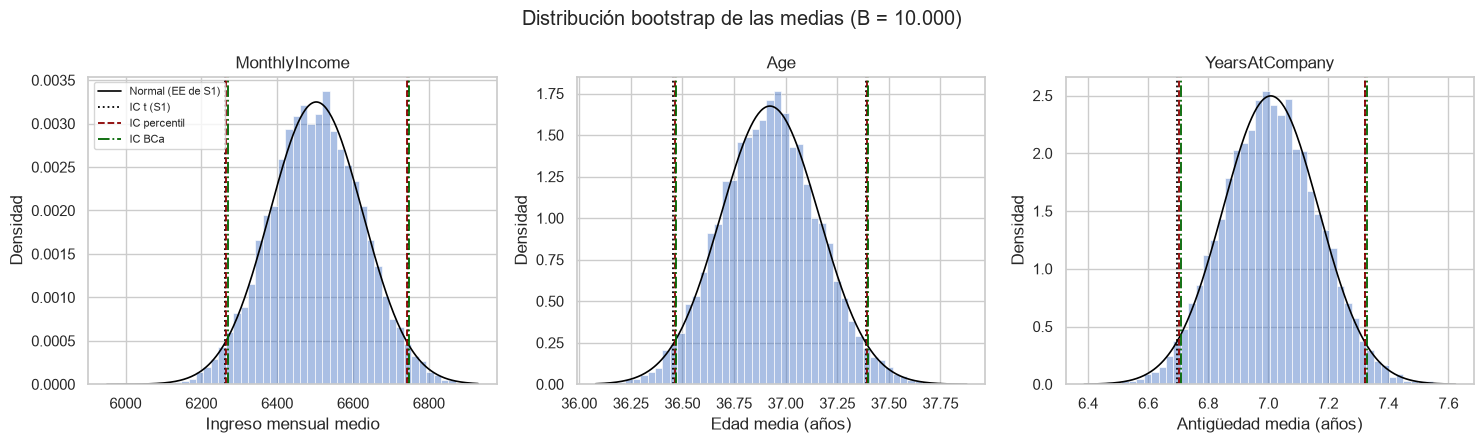

Figura guardada: S2/figuras/lenin_bootstrap_medias_distribuciones.png


In [17]:
etiquetas = {
    "MonthlyIncome": "Ingreso mensual medio",
    "Age": "Edad media (años)",
    "YearsAtCompany": "Antigüedad media (años)",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (_, fila) in zip(axes, bootstrap_medias.iterrows()):
    replicas = replicas_medias[fila["variable"]]

    sns.histplot(replicas, bins=50, stat="density",
                 color="#4472C4", alpha=0.45, ax=ax)

    # Curva normal implícita en el intervalo t de S1.
    malla = np.linspace(replicas.min(), replicas.max(), 300)
    ax.plot(malla, stats.norm.pdf(malla, fila["media"], fila["ee_s1"]),
            color="black", lw=1.2, label="Normal (EE de S1)")

    estilos = [("t", "black", ":", "IC t (S1)"),
               ("percentil", "darkred", "--", "IC percentil"),
               ("bca", "darkgreen", "-.", "IC BCa")]
    for metodo, color, linea, etiqueta in estilos:
        for k, lado in enumerate(["inferior", "superior"]):
            ax.axvline(fila[f"{metodo}_{lado}"], color=color, ls=linea,
                       lw=1.3, label=etiqueta if k == 0 else None)

    ax.set_xlabel(etiquetas[fila["variable"]])
    ax.set_ylabel("Densidad")
    ax.set_title(fila["variable"])

axes[0].legend(fontsize=8)
fig.suptitle(f"Distribución bootstrap de las medias (B = {B:,})".replace(",", "."))
fig.tight_layout()

ruta = carpeta_figuras / "lenin_bootstrap_medias_distribuciones.png"
fig.savefig(ruta, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada:", ruta.relative_to(raiz).as_posix())

#### Interpretación: medias

**Error estándar.** El error estándar bootstrap coincide con el analítico de S1 (s/√n): la razón es 0,985 para ingreso, 0,992 para edad y 1,001 para antigüedad. Las diferencias, de 1,5 % o menos, provienen sobre todo de la variación del propio remuestreo; el bootstrap no supone normalidad y llega al mismo valor.

**Intervalos percentil frente a t.** Los intervalos percentil son entre 0,4 % y 1,2 % más angostos que los t, y sus límites se desplazan como máximo 0,05 errores estándar. Para el ingreso mensual, el intervalo t es [6.262; 6.744] y el percentil [6.266; 6.742]. La diferencia práctica es nula.

**Intervalos BCa.** BCa desplaza los tres intervalos levemente hacia la derecha (z₀ y aceleración positivos) y alarga la cola superior entre 5 % y 8 % respecto de la inferior. Es la huella de la asimetría positiva de las variables, más marcada en ingreso y antigüedad: unos pocos sueldos o antigüedades altas pueden elevar la media de una remuestra más de lo que los valores bajos pueden reducirla. El mayor desplazamiento es de 0,09 errores estándar (límite inferior de antigüedad); en ingreso, el intervalo BCa es [6.271; 6.747], unas 9 unidades monetarias del dataset por encima del intervalo t en el límite inferior..

**Lectura de las discrepancias.** Aunque el ingreso mensual no es normal (figura QQ de S1), con n = 1.470 la distribución de su *media* sí es casi normal: la asimetría de las réplicas es 0,01 a 0,04 y el histograma se superpone con la curva normal de S1. La concordancia entre los tres métodos respalda el uso aproximado de los intervalos t de S1, bajo el supuesto de observaciones independientes y las limitaciones del conjunto sintético. La implementación manual de BCa concuerda con `scipy.stats.bootstrap` dentro de 0,05 errores estándar.

### B.4. Bootstrap de las correlaciones de Spearman

Para cada remuestra se sortean **filas completas**: el empleado i conserva su
par (x_i, y_i). Remuestrear cada variable por separado destruiría la asociación
y produciría correlaciones cercanas a cero.

Spearman equivale a la correlación de Pearson entre los rangos. En cada
remuestra se recalculan los rangos (con promedio en los empates, igual que
`pandas` y `scipy`), porque las observaciones repetidas cambian el orden.

Generador exclusivo: `SeedSequence([42, 3])`. Los mismos índices se usan para
los cuatro pares, lo que equivale a remuestrear empleados del dataset.

In [18]:
def spearman_por_fila(X, Y):
    """Spearman para cada fila de dos matrices (B x n)."""
    rx = stats.rankdata(X, axis=1)
    ry = stats.rankdata(Y, axis=1)
    rx -= rx.mean(axis=1, keepdims=True)
    ry -= ry.mean(axis=1, keepdims=True)
    return (rx * ry).sum(axis=1) / np.sqrt(
        (rx ** 2).sum(axis=1) * (ry ** 2).sum(axis=1)
    )


def spearman_jackknife(x, y):
    """Spearman omitiendo una observación a la vez."""
    mascara = ~np.eye(len(x), dtype=bool)
    X = np.broadcast_to(x, (len(x), len(x)))[mascara].reshape(len(x), -1)
    Y = np.broadcast_to(y, (len(y), len(y)))[mascara].reshape(len(y), -1)
    return spearman_por_fila(X, Y)


rng_correlaciones = np.random.default_rng(np.random.SeedSequence([SEMILLA, 3]))
indices_correlaciones = rng_correlaciones.integers(0, N, size=(B, N))

replicas_correlaciones = {}
filas_correlaciones = []

for _, ref in ref_correlaciones.iterrows():
    vx, vy = ref["variable_x"], ref["variable_y"]
    x = df[vx].to_numpy(dtype=float)
    y = df[vy].to_numpy(dtype=float)

    rho = stats.spearmanr(x, y).statistic
    assert np.isclose(rho, ref["rho_spearman"]), "No coincide con S1."

    replicas = spearman_por_fila(x[indices_correlaciones],
                                 y[indices_correlaciones])
    replicas_correlaciones[(vx, vy)] = replicas

    p_inf, p_sup = ic_percentil(replicas)
    (b_inf, b_sup), z0, a, _ = ic_bca(replicas, rho,
                                       spearman_jackknife(x, y))

    filas_correlaciones.append({
        "variable_x": vx,
        "variable_y": vy,
        "n": N,
        "B": B,
        "rho_s1": ref["rho_spearman"],
        "rho_bootstrap_media": replicas.mean(),
        "sesgo_bootstrap": replicas.mean() - rho,
        "ee_bootstrap": replicas.std(ddof=1),
        "percentil_inferior": p_inf,
        "percentil_superior": p_sup,
        "bca_inferior": b_inf,
        "bca_superior": b_sup,
        "bca_z0": z0,
        "bca_aceleracion": a,
        "ancho_bca": b_sup - b_inf,
        "proporcion_replicas_positivas": np.mean(replicas > 0),
        "ic_bca_incluye_cero": bool(b_inf <= 0 <= b_sup),
    })

bootstrap_correlaciones = pd.DataFrame(filas_correlaciones)
display(bootstrap_correlaciones.round(4))

,variable_x,variable_y,n,B,rho_s1,rho_bootstrap_media,sesgo_bootstrap,ee_bootstrap,percentil_inferior,percentil_superior,bca_inferior,bca_superior,bca_z0,bca_aceleracion,ancho_bca,proporcion_replicas_positivas,ic_bca_incluye_cero
0,MonthlyIncome,TotalWorkingYears,1470,10000,0.7100,0.7098,-0.0002,0.0153,0.6791,0.7394,0.6788,0.7392,0.0023,-0.0054,0.0604,1.0000,False
1,Age,TotalWorkingYears,1470,10000,0.6569,0.6566,-0.0003,0.0168,0.6231,0.6881,0.6227,0.6880,0.0058,-0.0062,0.0653,1.0000,False
2,YearsAtCompany,TotalWorkingYears,1470,10000,0.5942,0.5941,-0.0001,0.0216,0.5509,0.6349,0.5495,0.6340,-0.0186,-0.0082,0.0845,1.0000,False
3,DistanceFromHome,MonthlyIncome,1470,10000,0.0025,0.0025,-0.0000,0.0259,-0.0479,0.0529,-0.0482,0.0527,-0.0038,0.0002,0.1009,0.5409,True


#### B.4.1 Estabilidad de las correlaciones

Se resume la estabilidad de cada correlación con tres indicadores:

- **Coeficiente de variación** del bootstrap (EE / |ρ|): qué tan grande es la
  incertidumbre frente a la magnitud de la correlación.
- **Estabilidad del signo**: proporción de réplicas con el mismo signo que ρ.
- **Estabilidad de la intensidad**: proporción de réplicas que caen en la misma
  categoría descriptiva (|ρ| < 0,1 despreciable; 0,1–0,3 débil; 0,3–0,5
  moderada; 0,5–0,7 fuerte; ≥ 0,7 muy fuerte). Los cortes son convencionales;
  una correlación cerca de un corte será inestable en categoría aunque sea
  precisa.

Además, se revisa si los límites del intervalo percentil se estabilizan al
aumentar B (500 a 10.000), usando las primeras B réplicas.

In [19]:
cortes = [0, 0.1, 0.3, 0.5, 0.7, 1.0001]
nombres = ["despreciable", "débil", "moderada", "fuerte", "muy fuerte"]

def categoria(valor):
    return pd.cut(np.abs(np.atleast_1d(valor)), bins=cortes,
                  labels=nombres, right=False).astype(str)

filas_estabilidad = []

for _, fila in bootstrap_correlaciones.iterrows():
    replicas = replicas_correlaciones[(fila["variable_x"], fila["variable_y"])]
    rho = fila["rho_s1"]
    categoria_rho = categoria(rho)[0]
    categorias_replicas = pd.Series(categoria(replicas))

    filas_estabilidad.append({
        "par": f'{fila["variable_x"]} – {fila["variable_y"]}',
        "rho_s1": rho,
        "categoria_s1": categoria_rho,
        "ee_bootstrap": fila["ee_bootstrap"],
        "coef_variacion": fila["ee_bootstrap"] / abs(rho),
        "estabilidad_signo": np.mean(np.sign(replicas) == np.sign(rho)),
        "estabilidad_categoria": np.mean(categorias_replicas == categoria_rho),
        "categorias_observadas": ", ".join(
            f"{k}: {v:.2%}".replace(".", ",")
            for k, v in categorias_replicas.value_counts(normalize=True).items()
        ),
    })

estabilidad_correlaciones = pd.DataFrame(filas_estabilidad)
display(estabilidad_correlaciones.round(4))

# Estabilidad de los límites percentil según el número de remuestras.
filas_b = []
for (vx, vy), replicas in replicas_correlaciones.items():
    for b in [500, 1_000, 2_000, 5_000, 10_000]:
        inferior, superior = ic_percentil(replicas[:b])
        filas_b.append({"variable_x": vx, "variable_y": vy, "B": b,
                        "ee_bootstrap": replicas[:b].std(ddof=1),
                        "percentil_inferior": inferior,
                        "percentil_superior": superior})

convergencia_b = pd.DataFrame(filas_b)
display(convergencia_b.round(4))

,par,rho_s1,categoria_s1,ee_bootstrap,coef_variacion,estabilidad_signo,estabilidad_categoria,categorias_observadas
0,MonthlyIncome – TotalWorkingYears,0.7100,muy fuerte,0.0153,0.0216,1.0000,0.7394,"muy fuerte: 73,94%, fuerte: 26,06%"
1,Age – TotalWorkingYears,0.6569,fuerte,0.0168,0.0255,1.0000,0.9959,"fuerte: 99,59%, muy fuerte: 0,41%"
2,YearsAtCompany – TotalWorkingYears,0.5942,fuerte,0.0216,0.0364,1.0000,1.0000,"fuerte: 100,00%"
3,DistanceFromHome – MonthlyIncome,0.0025,despreciable,0.0259,10.3107,0.5409,0.9996,"despreciable: 99,96%, débil: 0,04%"


,variable_x,variable_y,B,ee_bootstrap,percentil_inferior,percentil_superior
0,MonthlyIncome,TotalWorkingYears,500,0.0156,0.6792,0.7392
1,MonthlyIncome,TotalWorkingYears,1000,0.0158,0.6787,0.7394
2,MonthlyIncome,TotalWorkingYears,2000,0.0154,0.6793,0.7391
3,MonthlyIncome,TotalWorkingYears,5000,0.0154,0.6790,0.7393
4,MonthlyIncome,TotalWorkingYears,10000,0.0153,0.6791,0.7394
5,Age,TotalWorkingYears,500,0.0168,0.6208,0.6861
6,Age,TotalWorkingYears,1000,0.0171,0.6214,0.6891
7,Age,TotalWorkingYears,2000,0.0168,0.6227,0.6884
8,Age,TotalWorkingYears,5000,0.0167,0.6230,0.6885
9,Age,TotalWorkingYears,10000,0.0168,0.6231,0.6881


#### B.4.2 ¿Es estable el orden entre las correlaciones?

Los intervalos de ingreso–experiencia y edad–experiencia se superponen levemente,
pero eso no basta para concluir que no difieren: ambos se calculan sobre los
mismos empleados y no son independientes. Como los cuatro pares se remuestrearon
con **los mismos índices**, se puede calcular la diferencia entre correlaciones
dentro de cada remuestra y obtener su intervalo percentil directamente.

In [20]:
etiquetas_pares = {
    ("MonthlyIncome", "TotalWorkingYears"): "Ingreso–Experiencia",
    ("Age", "TotalWorkingYears"): "Edad–Experiencia",
    ("YearsAtCompany", "TotalWorkingYears"): "Antigüedad–Experiencia",
}
claves = list(etiquetas_pares)

filas_diferencias = []
for i in range(len(claves)):
    for j in range(i + 1, len(claves)):
        a, b = claves[i], claves[j]
        diferencia = replicas_correlaciones[a] - replicas_correlaciones[b]
        inferior, superior = ic_percentil(diferencia)
        filas_diferencias.append({
            "comparacion": f"{etiquetas_pares[a]} − {etiquetas_pares[b]}",
            "diferencia_observada": (
                bootstrap_correlaciones.set_index(["variable_x", "variable_y"])
                .loc[a, "rho_s1"]
                - bootstrap_correlaciones.set_index(["variable_x", "variable_y"])
                .loc[b, "rho_s1"]
            ),
            "ee_bootstrap": diferencia.std(ddof=1),
            "percentil_inferior": inferior,
            "percentil_superior": superior,
            "proporcion_mayor": np.mean(diferencia > 0),
        })

diferencias_correlaciones = pd.DataFrame(filas_diferencias)
display(diferencias_correlaciones.round(4))

,comparacion,diferencia_observada,ee_bootstrap,percentil_inferior,percentil_superior,proporcion_mayor
0,Ingreso–Experiencia − Edad–Experiencia,0.0531,0.0191,0.0157,0.0905,0.9971
1,Ingreso–Experiencia − Antigüedad–Experiencia,0.1158,0.0243,0.0693,0.1642,1.0000
2,Edad–Experiencia − Antigüedad–Experiencia,0.0627,0.0275,0.0090,0.1173,0.9889


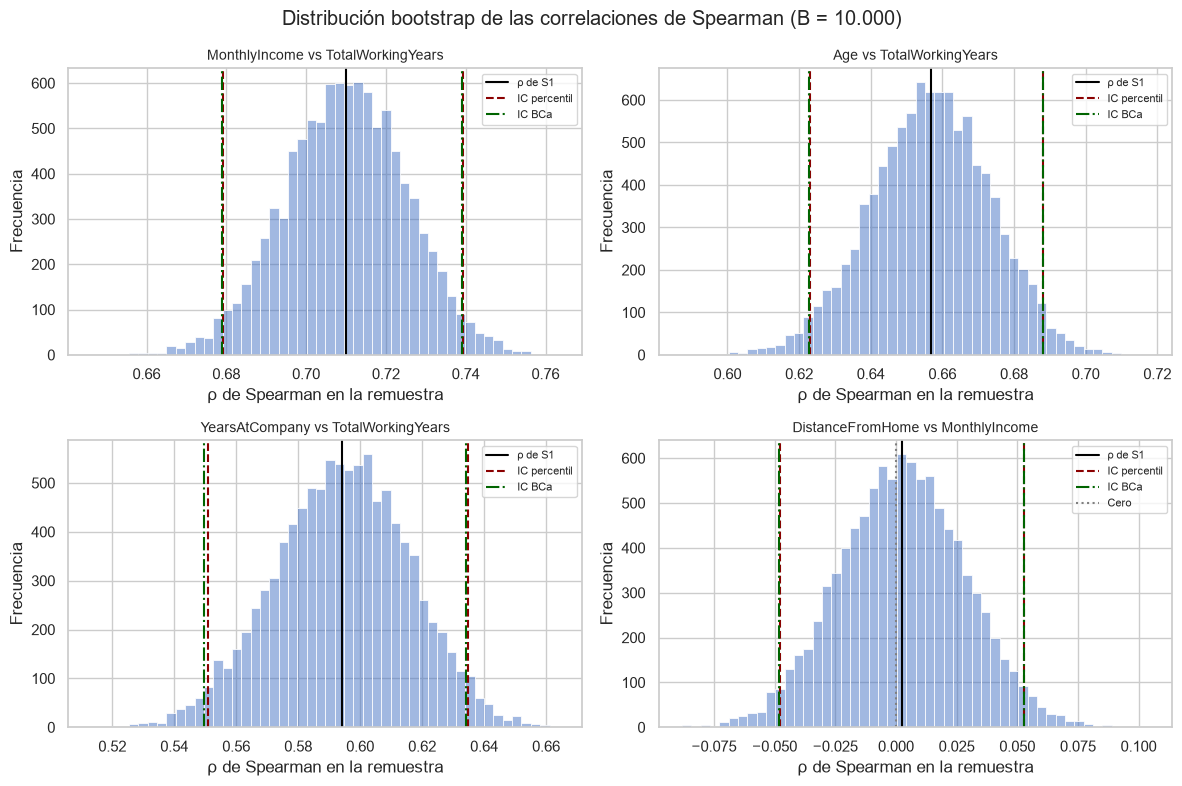

Figura guardada: S2/figuras/lenin_bootstrap_correlaciones_distribuciones.png


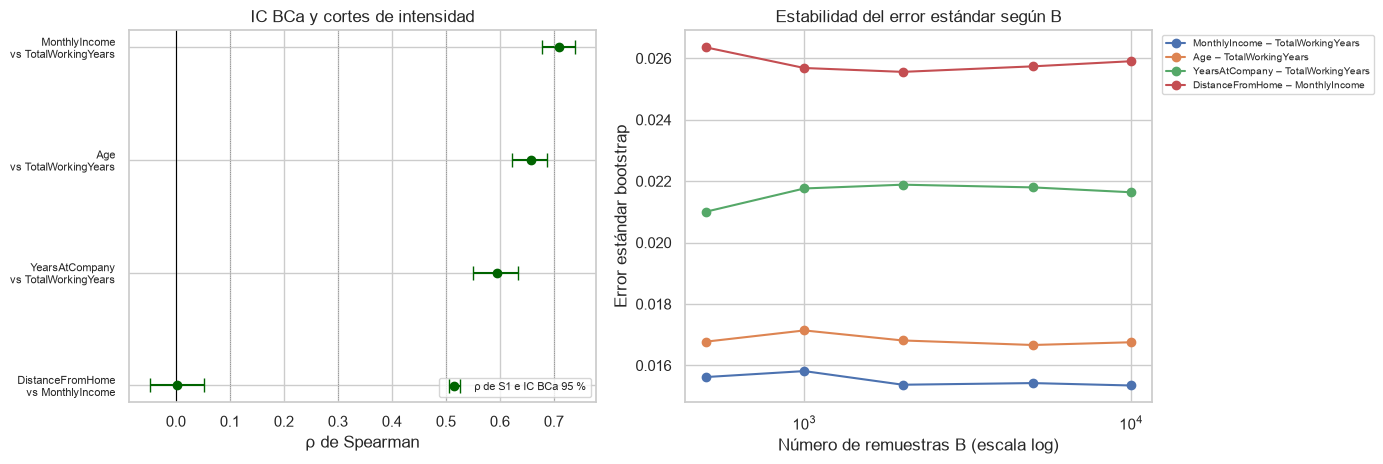

Figura guardada: S2/figuras/lenin_bootstrap_correlaciones_estabilidad.png


In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (_, fila) in zip(axes.ravel(), bootstrap_correlaciones.iterrows()):
    replicas = replicas_correlaciones[(fila["variable_x"], fila["variable_y"])]

    sns.histplot(replicas, bins=50, color="#4472C4", alpha=0.5, ax=ax)
    ax.axvline(fila["rho_s1"], color="black", lw=1.5, label="ρ de S1")
    for k, lado in enumerate(["inferior", "superior"]):
        ax.axvline(fila[f"percentil_{lado}"], color="darkred", ls="--",
                   label="IC percentil" if k == 0 else None)
        ax.axvline(fila[f"bca_{lado}"], color="darkgreen", ls="-.",
                   label="IC BCa" if k == 0 else None)
    if fila["ic_bca_incluye_cero"]:
        ax.axvline(0, color="grey", ls=":", label="Cero")

    ax.set_title(f'{fila["variable_x"]} vs {fila["variable_y"]}', fontsize=10)
    ax.set_xlabel("ρ de Spearman en la remuestra")
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=8)

fig.suptitle(
    f"Distribución bootstrap de las correlaciones de Spearman (B = {B:,})"
    .replace(",", ".")
)
fig.tight_layout()
ruta = carpeta_figuras / "lenin_bootstrap_correlaciones_distribuciones.png"
fig.savefig(ruta, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada:", ruta.relative_to(raiz).as_posix())

# Intervalos en una escala común y estabilidad respecto de B.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
pares = bootstrap_correlaciones.apply(
    lambda f: f'{f["variable_x"]}\nvs {f["variable_y"]}', axis=1
)
posiciones = np.arange(len(bootstrap_correlaciones))
ax.errorbar(
    bootstrap_correlaciones["rho_s1"], posiciones,
    xerr=[bootstrap_correlaciones["rho_s1"] - bootstrap_correlaciones["bca_inferior"],
          bootstrap_correlaciones["bca_superior"] - bootstrap_correlaciones["rho_s1"]],
    fmt="o", color="darkgreen", capsize=5, label="ρ de S1 e IC BCa 95 %"
)
for corte in [0.1, 0.3, 0.5, 0.7]:
    ax.axvline(corte, color="grey", lw=0.6, ls=":")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(posiciones, pares, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("ρ de Spearman")
ax.set_title("IC BCa y cortes de intensidad")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1]
for (vx, vy), datos in convergencia_b.groupby(["variable_x", "variable_y"], sort=False):
    ax.plot(datos["B"], datos["ee_bootstrap"], marker="o", label=f"{vx} – {vy}")
ax.set_xscale("log")
ax.set_xlabel("Número de remuestras B (escala log)")
ax.set_ylabel("Error estándar bootstrap")
ax.set_title("Estabilidad del error estándar según B")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))

fig.tight_layout()
ruta = carpeta_figuras / "lenin_bootstrap_correlaciones_estabilidad.png"
fig.savefig(ruta, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada:", ruta.relative_to(raiz).as_posix())

#### Interpretación: correlaciones

**Precisión.** El sesgo bootstrap es despreciable (|sesgo| ≤ 0,0003) y los errores estándar van de 0,015 a 0,026. Percentil y BCa difieren en menos de 0,0015, porque las distribuciones bootstrap son casi simétricas (z₀ y aceleración cercanos a cero).

**Las tres correlaciones con la experiencia total son estables.**

| Par | ρ S1 | IC BCa 95 % |
|---|---|---|
| Ingreso – experiencia | 0,710 | [0,679; 0,739] |
| Edad – experiencia | 0,657 | [0,623; 0,688] |
| Antigüedad – experiencia | 0,594 | [0,550; 0,634] |

Todas las réplicas son positivas y el coeficiente de variación está entre 2 % y 4 %. El orden también es estable: al comparar dentro de cada remuestra, ingreso–experiencia supera a edad–experiencia en el 99,7 % de las réplicas (diferencia 0,053; IC [0,016; 0,091]), y edad–experiencia supera a antigüedad–experiencia en el 98,9 % (diferencia 0,063; IC [0,009; 0,117]). Aunque los intervalos individuales de ingreso y edad se superponen, la diferencia pareada no incluye el cero.

**Estabilidad de la etiqueta frente a la del valor.** ρ = 0,710 para ingreso–experiencia queda justo sobre el corte convencional de 0,7: el 26 % de las réplicas cae en “fuerte” y el 74 % en “muy fuerte”. El valor es preciso, pero la etiqueta no; conviene informarla como una asociación fuerte, de 0,68 a 0,74, en vez de afirmar “muy fuerte”.

**Distancia – ingreso.** El intervalo BCa [−0,048; 0,053] incluye el cero y solo el 54 % de las réplicas es positivo: el signo es inestable, como lanzar una moneda. Lo que sí es estable es la conclusión: el 99,96 % de las réplicas queda en |ρ| < 0,1. El intervalo obtenido es compatible con una asociación monótona pequeña o nula entre distancia e ingreso, bajo los supuestos del análisis. El coeficiente de variación (10,3) no es útil aquí porque ρ está prácticamente en cero.

**Número de remuestras.** Desde B = 2.000 el error estándar varía menos de 2 % y, entre 5.000 y 10.000 remuestras, los límites percentil cambian en la tercera decimal. Las 10.000 remuestras son suficientes para estos intervalos.

**Alcance.** Las tres correlaciones altas comparten la variable experiencia total, que se acumula con la edad y con los años en la empresa; parte de la asociación es estructural. Spearman mide asociación monótona, no causalidad, y los datos son sintéticos.

### B.5. Exportación de resultados

Tablas sin redondear (`%.17g`), en UTF-8 con BOM, igual que las referencias S1.
Las réplicas se exportan para que el equipo pueda rehacer gráficos o integrar
resultados sin volver a remuestrear.

In [22]:
exportaciones = {
    "lenin_bootstrap_medias_ic.csv": bootstrap_medias,
    "lenin_bootstrap_medias_comparacion.csv": comparacion_medias,
    "lenin_bootstrap_medias_control_scipy.csv": control_scipy,
    "lenin_bootstrap_medias_replicas.csv": pd.DataFrame(
        {"remuestra": np.arange(1, B + 1), **replicas_medias}
    ),
    "lenin_bootstrap_correlaciones_ic.csv": bootstrap_correlaciones,
    "lenin_bootstrap_correlaciones_estabilidad.csv": estabilidad_correlaciones,
    "lenin_bootstrap_correlaciones_convergencia_b.csv": convergencia_b,
    "lenin_bootstrap_correlaciones_diferencias.csv": diferencias_correlaciones,
    "lenin_bootstrap_correlaciones_replicas.csv": pd.DataFrame(
        {"remuestra": np.arange(1, B + 1),
         **{f"{vx}__{vy}": r for (vx, vy), r in replicas_correlaciones.items()}}
    ),
}

for nombre, tabla in exportaciones.items():
    ruta = carpeta_resultados / nombre
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig", float_format="%.17g")
    print("Tabla guardada:", ruta.relative_to(raiz).as_posix())

Tabla guardada: S2/resultados/lenin_bootstrap_medias_ic.csv
Tabla guardada: S2/resultados/lenin_bootstrap_medias_comparacion.csv
Tabla guardada: S2/resultados/lenin_bootstrap_medias_control_scipy.csv
Tabla guardada: S2/resultados/lenin_bootstrap_medias_replicas.csv
Tabla guardada: S2/resultados/lenin_bootstrap_correlaciones_ic.csv
Tabla guardada: S2/resultados/lenin_bootstrap_correlaciones_estabilidad.csv
Tabla guardada: S2/resultados/lenin_bootstrap_correlaciones_convergencia_b.csv
Tabla guardada: S2/resultados/lenin_bootstrap_correlaciones_diferencias.csv
Tabla guardada: S2/resultados/lenin_bootstrap_correlaciones_replicas.csv


### B.6. Verificación de reproducibilidad

Se regeneran los índices con las mismas semillas y se comprueba que las réplicas
son idénticas. También se verifica que el dataset y las referencias S1 no
cambiaron durante la ejecución.

In [23]:
rng_verificacion = np.random.default_rng(np.random.SeedSequence([SEMILLA, 2]))
indices_verificacion = rng_verificacion.integers(0, N, size=(B, N))
for variable, replicas in replicas_medias.items():
    x = df[variable].to_numpy(dtype=float)
    assert np.array_equal(replicas, x[indices_verificacion].mean(axis=1))

rng_verificacion = np.random.default_rng(np.random.SeedSequence([SEMILLA, 3]))
indices_verificacion = rng_verificacion.integers(0, N, size=(B, N))
assert np.array_equal(indices_verificacion, indices_correlaciones)

assert sha256(ruta_datos) == huella_csv
assert df.equals(original)
for nombre, huella in huellas_referencias.items():
    assert sha256(carpeta_resultados / nombre) == huella, nombre

print("Reproducibilidad: correcta.")
print("Dataset original y referencias S1: sin modificaciones.")
print(f"Remuestras por estadístico: {B:,}".replace(",", "."))

Reproducibilidad: correcta.
Dataset original y referencias S1: sin modificaciones.
Remuestras por estadístico: 10.000


### B.7. Conclusiones del bloque

1. Los intervalos t de S1 para las medias de ingreso, edad y antigüedad se mantienen al usar bootstrap: las diferencias son menores al 10 % de un error estándar. La asimetría de las variables se refleja en un leve desplazamiento hacia la derecha del intervalo BCa, sin consecuencias prácticas con n = 1.470.
2. Las tres correlaciones positivas con la experiencia total son estables en signo, magnitud y orden. La de ingreso–experiencia está en el límite entre fuerte y muy fuerte, por lo que la etiqueta debe usarse con cautela.
3. La correlación entre distancia e ingreso no tiene un signo estable, pero su ausencia de asociación relevante es robusta.

**Supuestos y limitaciones.** El bootstrap supone que las filas son observaciones independientes e idénticamente distribuidas; si hubiera empleados agrupados (por ejemplo, por equipo), el error estándar estaría subestimado. El remuestreo cuantifica la variabilidad muestral, pero no corrige sesgos de selección ni hace representativo un conjunto de datos sintético. Estos resultados complementan, sin reemplazar, la simulación Monte Carlo de Hernán: aquí se mide la incertidumbre de los estimadores; allá, la variabilidad de escenarios con parámetros fijos.

## Bloque C. Permutación y análisis de robustez

In [24]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Localizar la raíz del repositorio.
nombre_csv = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
carpeta_actual = Path.cwd().resolve()

raiz = next(
    (
        carpeta
        for carpeta in [carpeta_actual, *carpeta_actual.parents]
        if (carpeta / "datos" / nombre_csv).is_file()
    ),
    None
)

if raiz is None:
    raise FileNotFoundError(
        "No se encontró el dataset en la carpeta datos del repositorio."
    )

ruta_datos = raiz / "datos" / nombre_csv
carpeta_resultados = raiz / "S2" / "resultados"
carpeta_figuras = raiz / "S2" / "figuras"

carpeta_resultados.mkdir(parents=True, exist_ok=True)
carpeta_figuras.mkdir(parents=True, exist_ok=True)

# Conservar el original y trabajar sobre una copia.
original = pd.read_csv(ruta_datos)
df = original.copy(deep=True)
huella_csv = hashlib.sha256(ruta_datos.read_bytes()).hexdigest()

SEMILLA = 42
N_PERMUTACIONES = 10_000
ALFA = 0.05

# Generador exclusivo de este bloque.
rng_permutacion = np.random.default_rng(
    np.random.SeedSequence([SEMILLA, 5])
)

sns.set_theme(style="whitegrid")

# Leer los resultados de S1 para compararlos con la permutación.
referencias_pruebas = pd.read_csv(
    carpeta_resultados / "S1_referencia_pruebas.csv",
    encoding="utf-8-sig",
    float_precision="round_trip"
)

print("Raíz del repositorio:", raiz)
print("Dimensiones del dataset:", df.shape)
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("Permutaciones previstas:", N_PERMUTACIONES)
display(referencias_pruebas)

Raíz del repositorio: C:\Users\hernan.saavedra\Documents\2026\Magister\Estadisticas\estadisticaComputacional
Dimensiones del dataset: (1470, 35)
Valores faltantes: 0
Filas duplicadas: 0
Permutaciones previstas: 10000


,prueba,estadistico,gl,valor_p,v_cramer,esperada_minima,diferencia_medias,ic95_inferior,ic95_superior
0,Chi-cuadrado sin correccion,89.043879,1.000000,3.861518e-21,0.246118,67.069388,NaN,NaN,NaN
1,Welch bilateral permanece menos sale,7.482622,412.740748,4.433589e-13,NaN,NaN,2045.646832,1508.243516,2583.050149


### C.1. Prueba de permutación: ingreso mensual según salida

In [25]:
# Grupos en el mismo orden utilizado en S1.
ingresos_no = df.loc[
    df["Attrition"] == "No", "MonthlyIncome"
].to_numpy(dtype=float)

ingresos_si = df.loc[
    df["Attrition"] == "Yes", "MonthlyIncome"
].to_numpy(dtype=float)


def welch_t_stat(x, y):
    """Diferencia de medias dividida por su error estándar de Welch."""
    error = np.sqrt(
        x.var(ddof=1) / len(x) + y.var(ddof=1) / len(y)
    )
    if error == 0:
        raise ValueError("El error estándar es cero.")
    return (x.mean() - y.mean()) / error


# Resultado paramétrico y referencia original de S1.
welch_original = stats.ttest_ind(
    ingresos_no, ingresos_si, equal_var=False
)

referencia_welch = referencias_pruebas.loc[
    referencias_pruebas["diferencia_medias"].notna()
].iloc[0]

t_obs = welch_t_stat(ingresos_no, ingresos_si)

assert np.isclose(t_obs, referencia_welch["estadistico"])
assert np.isclose(
    welch_original.pvalue,
    referencia_welch["valor_p"],
    rtol=1e-8,
    atol=0
)

# Reiniciar el generador permite reproducir esta celda por separado.
rng_permutacion = np.random.default_rng(
    np.random.SeedSequence([SEMILLA, 5])
)

combinados = np.concatenate([ingresos_no, ingresos_si])
n_no = len(ingresos_no)
t_permutados = np.empty(N_PERMUTACIONES)

for i in range(N_PERMUTACIONES):
    permutados = rng_permutacion.permutation(combinados)
    t_permutados[i] = welch_t_stat(
        permutados[:n_no], permutados[n_no:]
    )

# Contraste bilateral con corrección +1.
extremos = int(
    np.count_nonzero(np.abs(t_permutados) >= abs(t_obs))
)
p_permutacion = (extremos + 1) / (N_PERMUTACIONES + 1)

print("Orden de comparación: permanece − sale")
print(f"Tamaños de grupo: {len(ingresos_no)} y {len(ingresos_si)}")
print(f"t observado: {t_obs:.4f}")
print(f"Valor p de Welch en S1: {referencia_welch['valor_p']:.6g}")
print(f"Permutaciones: {N_PERMUTACIONES}")
print(f"Permutaciones tan extremas o más: {extremos}")
print(f"Valor p de permutación (+1): {p_permutacion:.8f}")
print(
    "Decisión con α = 0,05:",
    "Rechazar H0" if p_permutacion < ALFA else "No rechazar H0"
)

Orden de comparación: permanece − sale
Tamaños de grupo: 1233 y 237
t observado: 7.4826
Valor p de Welch en S1: 4.43359e-13
Permutaciones: 10000
Permutaciones tan extremas o más: 0
Valor p de permutación (+1): 0.00009999
Decisión con α = 0,05: Rechazar H0


#### Hipótesis, método e interpretación

Se compara el ingreso mensual medio entre quienes permanecen y quienes
salen, manteniendo el orden **permanece − sale**.

- **H₀:** las medias de ingreso mensual de ambos grupos son iguales.
- **H₁:** las medias de ingreso mensual son diferentes.
- **Nivel de significancia:** α = 0,05, fijado antes del contraste como
  umbral convencional para esta evaluación.

Se utiliza el estadístico t de Welch, que divide la diferencia de medias
por un error estándar que permite varianzas distintas. En cada una de las
10.000 permutaciones se reasignan los ingresos entre los grupos,
conservando sus tamaños, y se recalcula todo el estadístico.

El estadístico observado es t = 7,4826. Ninguna permutación produjo un valor
absoluto tan extremo como el observado. Aplicando la corrección
(b + 1)/(B + 1), el valor p de permutación es 0,00009999.

Este valor corresponde al mínimo que puede obtener este procedimiento
con 10.000 permutaciones; no significa que el valor p subyacente sea
exactamente 0,0001. La simulación no permite resolver valores tan pequeños
como el p de Welch de S1 (4,43359 × 10⁻¹³).

Ambos métodos rechazan H₀ con α = 0,05. La concordancia respalda la
conclusión de una diferencia de ingresos medios, favorable al grupo que
permanece. Su magnitud observada en S1 es de 2.045,65 unidades monetarias
del dataset, con IC del 95 % de [1.508,24; 2.583,05].

#### Supuestos y alcance

La permutación de etiquetas es exacta bajo intercambiabilidad, que requiere
distribuciones iguales bajo la hipótesis nula y observaciones independientes.
La igualdad de medias por sí sola no garantiza esa condición.

La studentización con Welch permite una justificación asintótica para
contrastar medias con varianzas diferentes, bajo condiciones de regularidad;
no convierte la prueba en exacta para muestras finitas en ese escenario.
Por ello, se utiliza como comprobación complementaria al contraste de S1.

Los datos son sintéticos y el análisis no controla otros factores.
La diferencia observada no demuestra que un menor ingreso cause la salida
ni permite establecer directamente una política de compensaciones.

### C.2. Análisis jackknife e identificación de empleados influyentes

In [26]:
ingresos = df["MonthlyIncome"].to_numpy(dtype=float)
permanece = df["Attrition"].eq("No").to_numpy()

n = len(ingresos)
n_no = int(permanece.sum())
n_si = int((~permanece).sum())

suma_no = ingresos[permanece].sum()
suma_si = ingresos[~permanece].sum()

media_global = ingresos.mean()
media_no = suma_no / n_no
media_si = suma_si / n_si
diferencia_original = media_no - media_si

# Media global al omitir cada observación.
medias_jackknife = (ingresos.sum() - ingresos) / (n - 1)

# Diferencia permanece − sale al omitir cada observación.
diferencias_jackknife = np.empty(n)

diferencias_jackknife[permanece] = (
    (suma_no - ingresos[permanece]) / (n_no - 1)
    - media_si
)

diferencias_jackknife[~permanece] = (
    media_no
    - (suma_si - ingresos[~permanece]) / (n_si - 1)
)

# Tabla independiente: no agregar columnas al dataset.
influencia_jackknife = df[
    ["EmployeeNumber", "MonthlyIncome", "Attrition"]
].copy()

influencia_jackknife["media_sin_empleado"] = medias_jackknife
influencia_jackknife["cambio_media"] = (
    medias_jackknife - media_global
)
influencia_jackknife["diferencia_sin_empleado"] = (
    diferencias_jackknife
)
influencia_jackknife["cambio_diferencia"] = (
    diferencias_jackknife - diferencia_original
)
influencia_jackknife["cambio_absoluto_media"] = (
    influencia_jackknife["cambio_media"].abs()
)
influencia_jackknife["cambio_absoluto_diferencia"] = (
    influencia_jackknife["cambio_diferencia"].abs()
)

print(f"Media global original: {media_global:.2f}")
print(f"Diferencia original (permanece − sale): {diferencia_original:.2f}")

print("\nCinco empleados más influyentes sobre la media global:")
display(
    influencia_jackknife.nlargest(5, "cambio_absoluto_media")[
        ["EmployeeNumber", "MonthlyIncome", "Attrition", "cambio_media"]
    ]
)

print("\nCinco empleados más influyentes sobre la diferencia:")
display(
    influencia_jackknife.nlargest(5, "cambio_absoluto_diferencia")[
        ["EmployeeNumber", "MonthlyIncome", "Attrition", "cambio_diferencia"]
    ]
)

print(
    "\nRango de la diferencia al omitir un empleado:",
    f"[{diferencias_jackknife.min():.2f}; "
    f"{diferencias_jackknife.max():.2f}]"
)
print(
    "La diferencia permanece positiva en todos los casos:",
    bool((diferencias_jackknife > 0).all())
)

influencia_jackknife.to_csv(
    carpeta_resultados / "rodrigo_jackknife_influencia.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

Media global original: 6502.93
Diferencia original (permanece − sale): 2045.65

Cinco empleados más influyentes sobre la media global:


,EmployeeNumber,MonthlyIncome,Attrition,cambio_media
190,259,19999,No,-9.187249
746,1035,19973,No,-9.169550
851,1191,19943,No,-9.149128
165,226,19926,No,-9.137555
568,787,19859,Yes,-9.091946



Cinco empleados más influyentes sobre la diferencia:


,EmployeeNumber,MonthlyIncome,Attrition,cambio_diferencia
568,787,19859,Yes,63.864013
749,1038,19845,Yes,63.804691
45,58,19545,Yes,62.533505
595,825,19246,Yes,61.266556
913,1277,18824,Yes,59.478420



Rango de la diferencia al omitir un empleado: [2029.64; 2109.51]
La diferencia permanece positiva en todos los casos: True


### C.3. Sensibilidad a ingresos extremos

In [27]:
# Los valores extremos no se consideran errores.
# El filtro IQR se utiliza solo como escenario de sensibilidad.
q1 = df["MonthlyIncome"].quantile(0.25)
q3 = df["MonthlyIncome"].quantile(0.75)
limite_superior = q3 + 1.5 * (q3 - q1)

df_sensibilidad = df.loc[
    df["MonthlyIncome"] <= limite_superior
].copy()


def resumir_welch(datos, escenario):
    x = datos.loc[
        datos["Attrition"] == "No", "MonthlyIncome"
    ].to_numpy(dtype=float)

    y = datos.loc[
        datos["Attrition"] == "Yes", "MonthlyIncome"
    ].to_numpy(dtype=float)

    resultado = stats.ttest_ind(x, y, equal_var=False)
    intervalo = resultado.confidence_interval(
        confidence_level=0.95
    )

    return {
        "escenario": escenario,
        "n_permanece": len(x),
        "n_sale": len(y),
        "media_permanece": x.mean(),
        "media_sale": y.mean(),
        "diferencia_medias": x.mean() - y.mean(),
        "t_welch": resultado.statistic,
        "gl": resultado.df,
        "valor_p": resultado.pvalue,
        "ic95_inferior": intervalo.low,
        "ic95_superior": intervalo.high,
        "rechaza_h0": bool(resultado.pvalue < ALFA)
    }


resumen_sensibilidad = pd.DataFrame([
    resumir_welch(df, "Original completo"),
    resumir_welch(
        df_sensibilidad,
        "Sensibilidad: sin ingresos sobre límite IQR"
    )
])

diferencia_base = resumen_sensibilidad.loc[
    0, "diferencia_medias"
]

resumen_sensibilidad["cambio_diferencia_pct"] = (
    100
    * (
        resumen_sensibilidad["diferencia_medias"]
        - diferencia_base
    )
    / diferencia_base
)

print(f"Límite superior IQR: {limite_superior:.2f}")
print("Registros excluidos en el escenario de sensibilidad:",
      len(df) - len(df_sensibilidad))

display(resumen_sensibilidad)

resumen_sensibilidad.to_csv(
    carpeta_resultados / "rodrigo_resumen_sensibilidad.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

Límite superior IQR: 16581.00
Registros excluidos en el escenario de sensibilidad: 114


,escenario,n_permanece,n_sale,media_permanece,media_sale,diferencia_medias,t_welch,gl,valor_p,ic95_inferior,ic95_superior,rechaza_h0,cambio_diferencia_pct
0,Original completo,1233,237,6832.739659,4787.092827,2045.646832,7.482622,412.740748,4.433589e-13,1508.243516,2583.050149,True,0.000000
1,Sensibilidad: sin ingresos sobre límite IQR,1124,232,5715.769573,4470.784483,1244.985090,5.694497,363.968534,2.552690e-08,815.049468,1674.920713,True,-39.139784


#### Interpretación del análisis de robustez

El jackknife muestra que, al retirar un empleado a la vez, la diferencia
de ingresos medios entre quienes permanecen y quienes salen se mantiene
positiva, entre 2.029,64 y 2.109,51 unidades monetarias del dataset.
Por tanto, ningún registro individual revierte la dirección de la diferencia.

Como escenario de sensibilidad, se excluyeron 114 registros con ingresos
superiores a 16.581, límite definido mediante Q3 + 1,5 × IQR.
Estos valores no se consideran errores y se mantienen en el análisis principal.

Con el filtro, la diferencia media disminuye de 2.045,65 a 1.244,99 unidades,
una reducción del 39,14 %. El intervalo de confianza de Welch del 95 %
es [815,05; 1.674,92] y el valor p es aproximadamente 2,55 × 10⁻⁸.
La diferencia continúa siendo positiva y estadísticamente significativa.

En consecuencia, la dirección de la asociación y la decisión del contraste
se mantienen en los escenarios examinados, mientras que la magnitud de la
diferencia es sensible a la exclusión conjunta de los ingresos altos.
El escenario filtrado describe una población restringida por ingreso;
no constituye una corrección del dataset ni estima exactamente el mismo
parámetro que el análisis completo.

Para la siguiente fase se recomienda conservar los datos completos,
examinar el papel del cargo y del nivel laboral en las diferencias de ingreso
y complementar las medias con medidas menos sensibles a extremos.
Los resultados no establecen causalidad y su alcance está limitado
por el carácter sintético de los datos.

### C.4. Visualización y exportación de resultados

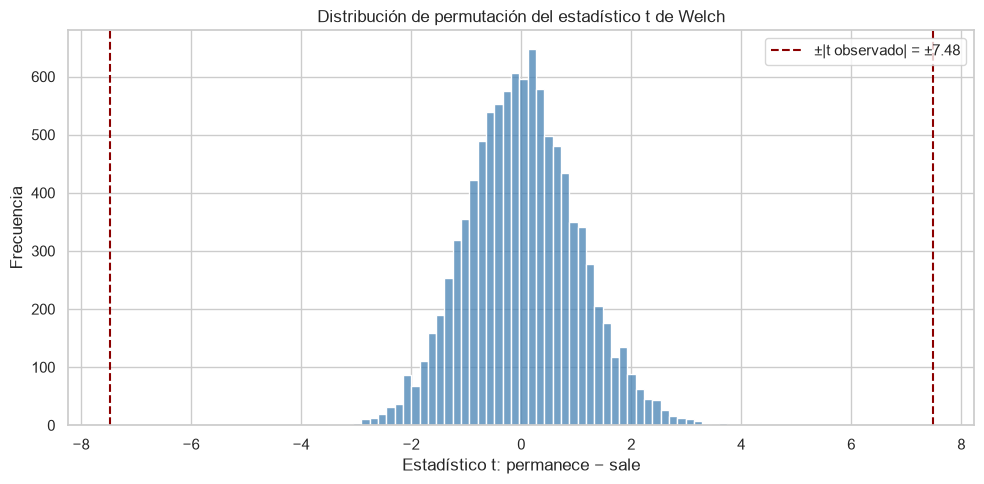

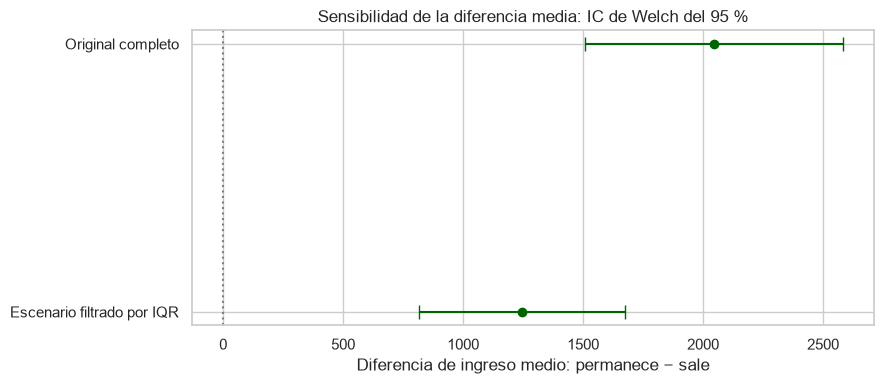

Figuras guardadas en: C:\Users\hernan.saavedra\Documents\2026\Magister\Estadisticas\estadisticaComputacional\S2\figuras
Resultados guardados en: C:\Users\hernan.saavedra\Documents\2026\Magister\Estadisticas\estadisticaComputacional\S2\resultados
Dataset original: sin modificaciones.


In [28]:
# Distribución de permutación: marcar ambas colas del contraste bilateral.
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    t_permutados,
    bins=50,
    color="steelblue",
    ax=ax
)

ax.axvline(
    abs(t_obs), color="darkred", linestyle="--",
    label=f"±|t observado| = ±{abs(t_obs):.2f}"
)
ax.axvline(
    -abs(t_obs), color="darkred", linestyle="--"
)

ax.set(
    title="Distribución de permutación del estadístico t de Welch",
    xlabel="Estadístico t: permanece − sale",
    ylabel="Frecuencia"
)
ax.legend()
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "rodrigo_permutacion_distribucion.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Comparación de diferencias medias e intervalos de Welch.
fig, ax = plt.subplots(figsize=(9, 4))

posiciones = np.arange(len(resumen_sensibilidad))
diferencias = resumen_sensibilidad["diferencia_medias"].to_numpy()

ax.errorbar(
    diferencias,
    posiciones,
    xerr=[
        diferencias - resumen_sensibilidad["ic95_inferior"].to_numpy(),
        resumen_sensibilidad["ic95_superior"].to_numpy() - diferencias
    ],
    fmt="o",
    capsize=5,
    color="darkgreen"
)
ax.axvline(0, color="grey", linestyle=":")
ax.set_yticks(
    posiciones,
    ["Original completo", "Escenario filtrado por IQR"]
)
ax.invert_yaxis()
ax.set(
    title="Sensibilidad de la diferencia media: IC de Welch del 95 %",
    xlabel="Diferencia de ingreso medio: permanece − sale"
)
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "rodrigo_sensibilidad_diferencias.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Guardar las permutaciones y su comparación con S1.
pd.DataFrame({
    "permutacion": np.arange(1, N_PERMUTACIONES + 1),
    "t_permutado": t_permutados
}).to_csv(
    carpeta_resultados / "rodrigo_permutacion_replicas.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

resumen_permutacion = pd.DataFrame([{
    "comparacion": "permanece - sale",
    "n_permanece": len(ingresos_no),
    "n_sale": len(ingresos_si),
    "t_observado": t_obs,
    "p_welch_s1": referencia_welch["valor_p"],
    "permutaciones": N_PERMUTACIONES,
    "extremos": extremos,
    "p_permutacion": p_permutacion,
    "resolucion_minima_p": 1 / (N_PERMUTACIONES + 1),
    "alfa": ALFA,
    "semilla": SEMILLA,
    "flujo_aleatorio": 5,
    "rechaza_h0": bool(p_permutacion < ALFA)
}])

resumen_permutacion.to_csv(
    carpeta_resultados / "rodrigo_permutacion_resumen.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

# Comprobar que el análisis conservó los datos originales.
assert df.equals(original)
assert hashlib.sha256(ruta_datos.read_bytes()).hexdigest() == huella_csv

print("Figuras guardadas en:", carpeta_figuras)
print("Resultados guardados en:", carpeta_resultados)
print("Dataset original: sin modificaciones.")

## Bloque D. Síntesis de resultados validados para la Sumativa 3

Se reúnen los resultados de bootstrap, correlaciones, permutación,
simulación Monte Carlo y sensibilidad. La valoración de robustez se limita
a los procedimientos y escenarios examinados; no implica validez externa
ni permite establecer causalidad.

In [29]:
# Leer las exportaciones de cada bloque, conservando su precisión.
def leer_resultado(nombre):
    return pd.read_csv(
        carpeta_resultados / nombre,
        encoding="utf-8-sig",
        float_precision="round_trip"
    )


medias_validadas = leer_resultado("lenin_bootstrap_medias_ic.csv")
correlaciones_validadas = leer_resultado(
    "lenin_bootstrap_correlaciones_ic.csv"
)
permutacion_validada = leer_resultado(
    "rodrigo_permutacion_resumen.csv"
)
sensibilidad_validada = leer_resultado(
    "rodrigo_resumen_sensibilidad.csv"
)
mc_validado = leer_resultado("hernan_mc_resumen.csv")

filas = []

for _, fila in medias_validadas.iterrows():
    filas.append({
        "bloque": "Media",
        "resultado": fila["variable"],
        "estimacion": fila["media"],
        "ic95_inferior": fila["bca_inferior"],
        "ic95_superior": fila["bca_superior"],
        "metodo": "Bootstrap BCa, 10.000 remuestras",
        "valoracion": (
            "Concordancia entre IC t, percentil y BCa "
            "en el dataset completo"
        ),
        "recomendacion_s3": (
            "Conservar la estimacion y su incertidumbre; "
            "para ingreso, considerar sensibilidad a extremos"
        )
    })

for _, fila in correlaciones_validadas.iterrows():
    incluye_cero = (
        fila["bca_inferior"] <= 0 <= fila["bca_superior"]
    )

    filas.append({
        "bloque": "Correlacion",
        "resultado": (
            f'{fila["variable_x"]} - {fila["variable_y"]}'
        ),
        "estimacion": fila["rho_s1"],
        "ic95_inferior": fila["bca_inferior"],
        "ic95_superior": fila["bca_superior"],
        "metodo": "Spearman y bootstrap pareado BCa",
        "valoracion": (
            "Signo incierto; compatible con asociacion pequena o nula"
            if incluye_cero
            else "Signo positivo estable en el remuestreo"
        ),
        "recomendacion_s3": (
            "Examinar asociaciones estructurales y redundancia; "
            "no interpretar como causalidad"
        )
    })

validacion_estimaciones = pd.DataFrame(filas)

validacion_estimaciones.to_csv(
    carpeta_resultados / "S2_resultados_validados_S3.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

# Reporte complementario con todos los bloques e influencia individual.
import json

reporte_s3 = {
    "equipo": ["Hernan Saavedra", "Lenin Salas", "Rodrigo Gomez"],
    "dataset": {
        "archivo": ruta_datos.relative_to(raiz).as_posix(),
        "sha256": hashlib.sha256(ruta_datos.read_bytes()).hexdigest(),
        "registros": len(original),
        "naturaleza": "Sintetico"
    },
    "estimaciones_y_correlaciones": (
        validacion_estimaciones.to_dict(orient="records")
    ),
    "permutacion": permutacion_validada.to_dict(orient="records"),
    "sensibilidad": sensibilidad_validada.to_dict(orient="records"),
    "monte_carlo": mc_validado.to_dict(orient="records"),
    "influencia_jackknife": {
        "diferencia_minima": float(diferencias_jackknife.min()),
        "diferencia_maxima": float(diferencias_jackknife.max()),
        "empleados_mayor_influencia_diferencia": (
            influencia_jackknife.nlargest(
                5, "cambio_absoluto_diferencia"
            ).to_dict(orient="records")
        )
    },
    "recomendaciones_s3": [
        "Conservar el dataset completo como analisis principal.",
        "Distinguir estabilidad del signo y sensibilidad de la magnitud.",
        "Examinar cargo, nivel laboral y experiencia como posibles factores.",
        "Revisar redundancia entre edad, experiencia y antiguedad.",
        "Conservar EmployeeNumber como identificador de trazabilidad.",
        "Distinguir incertidumbre de estimadores y escenarios con parametros fijos.",
        "No generalizar a una empresa real ni atribuir causalidad."
    ]
}

ruta_reporte = carpeta_resultados / "S2_reporte_validado_S3.json"
ruta_reporte.write_text(
    json.dumps(reporte_s3, ensure_ascii=False, indent=2, allow_nan=False),
    encoding="utf-8"
)

display(validacion_estimaciones)
print("Archivo creado: S2_resultados_validados_S3.csv")
print("Archivo creado: S2_reporte_validado_S3.json")

,bloque,resultado,estimacion,ic95_inferior,ic95_superior,metodo,valoracion,recomendacion_s3
0,Media,MonthlyIncome,6502.931293,6271.320174,6747.301284,"Bootstrap BCa, 10.000 remuestras","Concordancia entre IC t, percentil y BCa en el...",Conservar la estimacion y su incertidumbre; pa...
1,Media,Age,36.923810,36.470068,37.399737,"Bootstrap BCa, 10.000 remuestras","Concordancia entre IC t, percentil y BCa en el...",Conservar la estimacion y su incertidumbre; pa...
2,Media,YearsAtCompany,7.008163,6.709524,7.329420,"Bootstrap BCa, 10.000 remuestras","Concordancia entre IC t, percentil y BCa en el...",Conservar la estimacion y su incertidumbre; pa...
3,Correlacion,MonthlyIncome - TotalWorkingYears,0.710024,0.678812,0.739173,Spearman y bootstrap pareado BCa,Signo positivo estable en el remuestreo,Examinar asociaciones estructurales y redundan...
4,Correlacion,Age - TotalWorkingYears,0.656896,0.622690,0.687959,Spearman y bootstrap pareado BCa,Signo positivo estable en el remuestreo,Examinar asociaciones estructurales y redundan...
5,Correlacion,YearsAtCompany - TotalWorkingYears,0.594193,0.549546,0.634012,Spearman y bootstrap pareado BCa,Signo positivo estable en el remuestreo,Examinar asociaciones estructurales y redundan...
6,Correlacion,DistanceFromHome - MonthlyIncome,0.002512,-0.048208,0.052731,Spearman y bootstrap pareado BCa,Signo incierto; compatible con asociacion pequ...,Examinar asociaciones estructurales y redundan...


Archivo creado: S2_resultados_validados_S3.csv
Archivo creado: S2_reporte_validado_S3.json
